In [41]:
%pip install matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 6.3 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.3 MB 5.0 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/9.3 MB 3.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.3 MB 3.8 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.3 MB 3.1 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.3 MB 3.3 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.3 MB 3.0 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 3.4 MB/s eta 0:00:02
   ------------------------------- -------- 7.3/9.3 MB 4.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 3.6 MB/s eta 0:00:01
   --------------------------------- -----


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_data1 = pd.read_csv("Dataset/train_part1.csv")
train_data2 = pd.read_csv("Dataset/train_part2.csv")
test_data1 = pd.read_csv("Dataset/test_part1.csv")
test_data2 = pd.read_csv("Dataset/test_part2.csv")

In [3]:
train_data = pd.concat([train_data1, train_data2], ignore_index=True)

In [4]:
train_data

,ListingID,City,Locality,PropertyType,BHK,Bathrooms,Balconies,Furnishing,SuperBuiltUpArea_sqft,BuiltUpArea_sqft,...,BuildingType,YearBuilt,AgeYears,Facing,AmenitiesCount,IsRERARegistered,RERAID,Latitude,Longitude,Price_INR
0,HP01139,Bengaluru,NaN,Villa,3,3.0,2.0,Semi-Furnished,1576,1299,...,Bungalow,2018.0,7,South-East,3,True,BEN-RERA-9928-63,12.877154,77.656243,17770000
1,HP01630,Kolkata,Rajarhat,Apartment,1,2.0,1.0,Unfurnished,1098,870,...,Mid Rise,2010.0,15,North-West,9,True,KOL-RERA-6820-36,22.584035,88.440364,7130000
2,HP01608,Kolkata,Salt Lake,Apartment,1,2.0,3.0,Unfurnished,863,710,...,High Rise,2006.0,19,South,6,True,KOL-RERA-5304-84,22.535687,88.416707,5920000
3,HP01979,MMR,Goregaon East,Apartment,2,3.0,NaN,Furnished,1135,952,...,High Rise,2025.0,0,North-East,7,False,NaN,NaN,72.877790,19140000
4,HP01399,Hyderabad,Madhapur,Apartment,3,4.0,1.0,Semi-Furnished,2662,2176,...,Standalone Building,2010.0,15,North,6,True,HYD-RERA-7537-95,17.444963,78.431430,20300000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4723,HP00733,Chennai,Porur,Penthouse,4,5.0,3.0,Unfurnished,2670,2228,...,High Rise,2008.0,17,South-East,9,True,CHE-RERA-1823-72,13.077017,80.344260,26250000
4724,HP00905,Hyderabad,Kukatpally,Villa,5,5.0,3.0,Furnished,5077,4181,...,Standalone Building,2004.0,21,West,9,True,HYD-RERA-4007-79,17.460544,78.436887,48420000
4725,HP00542,Delhi NCR,Noida-Sector 62,Apartment,3,3.0,1.0,Unfurnished,2092,1590,...,Gated Community,1997.0,28,North,10,False,NaN,28.776437,77.033101,16880000
4726,HP01215,MMR,Vile Parle,Apartment,2,3.0,2.0,Semi-Furnished,1083,905,...,Mid Rise,2010.0,15,North-West,7,True,MMR-RERA-7553-86,19.060848,72.800001,17560000


In [5]:
test_data = pd.concat(
    [test_data1, test_data2],
    ignore_index=True
)

print("Combined test_data shape:", test_data.shape)

Combined test_data shape: (4728, 23)


In [6]:
train_data.tail()

,ListingID,City,Locality,PropertyType,BHK,Bathrooms,Balconies,Furnishing,SuperBuiltUpArea_sqft,BuiltUpArea_sqft,...,BuildingType,YearBuilt,AgeYears,Facing,AmenitiesCount,IsRERARegistered,RERAID,Latitude,Longitude,Price_INR
4723,HP00733,Chennai,Porur,Penthouse,4,5.0,3.0,Unfurnished,2670,2228,...,High Rise,2008.0,17,South-East,9,True,CHE-RERA-1823-72,13.077017,80.344260,26250000
4724,HP00905,Hyderabad,Kukatpally,Villa,5,5.0,3.0,Furnished,5077,4181,...,Standalone Building,2004.0,21,West,9,True,HYD-RERA-4007-79,17.460544,78.436887,48420000
4725,HP00542,Delhi NCR,Noida-Sector 62,Apartment,3,3.0,1.0,Unfurnished,2092,1590,...,Gated Community,1997.0,28,North,10,False,NaN,28.776437,77.033101,16880000
4726,HP01215,MMR,Vile Parle,Apartment,2,3.0,2.0,Semi-Furnished,1083,905,...,Mid Rise,2010.0,15,North-West,7,True,MMR-RERA-7553-86,19.060848,72.800001,17560000
4727,HP00443,Chennai,OMR,Apartment,1,2.0,3.0,Unfurnished,900,709,...,Gated Community,1999.0,26,South-East,9,True,CHE-RERA-2546-26,13.187485,80.307801,7810000


In [7]:
train_data.dtypes

ListingID                    str
City                         str
Locality                     str
PropertyType                 str
BHK                        int64
Bathrooms                float64
Balconies                float64
Furnishing                   str
SuperBuiltUpArea_sqft      int64
BuiltUpArea_sqft           int64
CarpetArea_sqft            int64
Floor                      int64
TotalFloors                int64
Parking                      str
BuildingType                 str
YearBuilt                float64
AgeYears                   int64
Facing                       str
AmenitiesCount             int64
IsRERARegistered            bool
RERAID                       str
Latitude                 float64
Longitude                float64
Price_INR                  int64
dtype: object

In [8]:
train_data.shape

(4728, 24)

In [9]:
train_data.columns

Index(['ListingID', 'City', 'Locality', 'PropertyType', 'BHK', 'Bathrooms',
       'Balconies', 'Furnishing', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft',
       'CarpetArea_sqft', 'Floor', 'TotalFloors', 'Parking', 'BuildingType',
       'YearBuilt', 'AgeYears', 'Facing', 'AmenitiesCount', 'IsRERARegistered',
       'RERAID', 'Latitude', 'Longitude', 'Price_INR'],
      dtype='str')

In [10]:
train_data.describe()

,BHK,Bathrooms,Balconies,SuperBuiltUpArea_sqft,BuiltUpArea_sqft,CarpetArea_sqft,Floor,TotalFloors,YearBuilt,AgeYears,AmenitiesCount,Latitude,Longitude,Price_INR
count,4728.000000,4674.000000,4628.000000,4728.000000,4728.000000,4728.000000,4728.000000,4728.000000,4689.000000,4728.000000,4728.000000,4678.000000,4669.000000,4.728000e+03
mean,2.551819,3.228070,1.524417,1976.857234,1563.064086,1333.160321,6.516286,12.504653,2014.146726,10.856176,7.022208,19.374590,77.571982,1.853415e+07
std,1.278891,1.243935,0.706609,1042.352626,809.452530,673.568980,7.375319,10.698632,7.427250,7.424854,1.590023,4.967147,4.736063,1.276603e+07
min,0.000000,1.000000,0.000000,406.000000,336.000000,300.000000,0.000000,1.000000,1985.000000,0.000000,3.000000,12.800641,72.400121,2.000000e+06
25%,2.000000,2.000000,1.000000,1237.000000,989.000000,854.000000,1.000000,4.000000,2009.000000,5.000000,6.000000,13.186363,73.753105,1.007000e+07
50%,3.000000,3.000000,1.000000,1765.000000,1404.500000,1208.000000,4.000000,9.000000,2015.000000,10.000000,7.000000,18.643519,77.462390,1.531000e+07
75%,3.000000,4.000000,2.000000,2512.000000,1992.250000,1702.000000,9.000000,18.000000,2020.000000,16.000000,8.000000,22.906225,78.594666,2.333000e+07
max,6.000000,7.000000,3.000000,6896.000000,5297.000000,4185.000000,39.000000,40.000000,2025.000000,40.000000,12.000000,28.799692,88.499776,1.342000e+08


In [11]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4728 entries, 0 to 4727
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ListingID              4728 non-null   str    
 1   City                   4678 non-null   str    
 2   Locality               4658 non-null   str    
 3   PropertyType           4728 non-null   str    
 4   BHK                    4728 non-null   int64  
 5   Bathrooms              4674 non-null   float64
 6   Balconies              4628 non-null   float64
 7   Furnishing             4645 non-null   str    
 8   SuperBuiltUpArea_sqft  4728 non-null   int64  
 9   BuiltUpArea_sqft       4728 non-null   int64  
 10  CarpetArea_sqft        4728 non-null   int64  
 11  Floor                  4728 non-null   int64  
 12  TotalFloors            4728 non-null   int64  
 13  Parking                4288 non-null   str    
 14  BuildingType           4728 non-null   str    
 15  YearBuilt      

In [12]:
train_data = train_data.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", train_data.shape)

Dataset shape after removing duplicates: (4728, 24)


In [13]:
missing_values = train_data.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
ListingID                  0
City                      50
Locality                  70
PropertyType               0
BHK                        0
Bathrooms                 54
Balconies                100
Furnishing                83
SuperBuiltUpArea_sqft      0
BuiltUpArea_sqft           0
CarpetArea_sqft            0
Floor                      0
TotalFloors                0
Parking                  440
BuildingType               0
YearBuilt                 39
AgeYears                   0
Facing                   108
AmenitiesCount             0
IsRERARegistered           0
RERAID                   950
Latitude                  50
Longitude                 59
Price_INR                  0
dtype: int64


In [14]:
missing_values[missing_values > 0]

City           50
Locality       70
Bathrooms      54
Balconies     100
Furnishing     83
Parking       440
YearBuilt      39
Facing        108
RERAID        950
Latitude       50
Longitude      59
dtype: int64

In [15]:
missing_percentage = (
    train_data.isnull().sum() / len(train_data) * 100
).round(2)

missing_summary = pd.DataFrame({
    'Missing_Count': train_data.isnull().sum(),
    'Missing_Percentage': missing_percentage
})

print(missing_summary[missing_summary['Missing_Count'] > 0])

            Missing_Count  Missing_Percentage
City                   50                1.06
Locality               70                1.48
Bathrooms              54                1.14
Balconies             100                2.12
Furnishing             83                1.76
Parking               440                9.31
YearBuilt              39                0.82
Facing                108                2.28
RERAID                950               20.09
Latitude               50                1.06
Longitude              59                1.25


## 5. Handling Missing Values

Missing values are handled according to the type and meaning of each
feature rather than removing all incomplete records.

Categorical variables are filled with an appropriate category such as
"Unknown" or "Not Specified", while numerical variables are imputed
using their median values.

RERAID is treated separately because a missing RERA ID can be meaningful
when a property is not registered under RERA.

In [16]:
categorical_fill = {
    'City': 'Unknown',
    'Locality': 'Unknown',
    'Furnishing': 'Unknown',
    'Parking': 'Not Specified',
    'Facing': 'Unknown',
    'RERAID': 'Not Available'
}

for col, value in categorical_fill.items():
    train_data[col] = train_data[col].fillna(value)

In [17]:
numerical_fill = [
    'Bathrooms',
    'Balconies',
    'YearBuilt',
    'Latitude',
    'Longitude'
]

for col in numerical_fill:
    train_data[col] = train_data[col].fillna(
        train_data[col].median()
    )

In [18]:
missing_after = train_data.isnull().sum()

print("Missing values after treatment:")
print(missing_after[missing_after > 0])

Missing values after treatment:
Series([], dtype: int64)


## 6. Data Type Validation

In this step, we verify that each feature has the appropriate data type.

Correct data types are important because numerical columns are required
for calculations and statistical analysis, while categorical columns
are used for grouping, filtering, and visualization.

In [19]:
print(train_data.dtypes)

ListingID                    str
City                         str
Locality                     str
PropertyType                 str
BHK                        int64
Bathrooms                float64
Balconies                float64
Furnishing                   str
SuperBuiltUpArea_sqft      int64
BuiltUpArea_sqft           int64
CarpetArea_sqft            int64
Floor                      int64
TotalFloors                int64
Parking                      str
BuildingType                 str
YearBuilt                float64
AgeYears                   int64
Facing                       str
AmenitiesCount             int64
IsRERARegistered            bool
RERAID                       str
Latitude                 float64
Longitude                float64
Price_INR                  int64
dtype: object


In [20]:
numerical_columns = train_data.select_dtypes(
    include=np.number
).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['BHK', 'Bathrooms', 'Balconies', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'YearBuilt', 'AgeYears', 'AmenitiesCount', 'Latitude', 'Longitude', 'Price_INR']


In [21]:
categorical_columns = train_data.select_dtypes(
    include=['object', 'string']
).columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['ListingID', 'City', 'Locality', 'PropertyType', 'Furnishing', 'Parking', 'BuildingType', 'Facing', 'RERAID']


In [22]:
expected_numeric = [
    'BHK',
    'Bathrooms',
    'Balconies',
    'SuperBuiltUpArea_sqft',
    'BuiltUpArea_sqft',
    'CarpetArea_sqft',
    'Floor',
    'TotalFloors',
    'YearBuilt',
    'AgeYears',
    'AmenitiesCount',
    'Latitude',
    'Longitude',
    'Price_INR'
]

for col in expected_numeric:
    print(f"{col}: {train_data[col].dtype}")

BHK: int64
Bathrooms: float64
Balconies: float64
SuperBuiltUpArea_sqft: int64
BuiltUpArea_sqft: int64
CarpetArea_sqft: int64
Floor: int64
TotalFloors: int64
YearBuilt: float64
AgeYears: int64
AmenitiesCount: int64
Latitude: float64
Longitude: float64
Price_INR: int64


## 7. Data Consistency and Validity Checks

After handling missing values and validating data types, the dataset is
checked for logically invalid or inconsistent values.

Real-estate data can contain values such as zero or negative property
areas, invalid BHK counts, impossible building ages, or prices that
require further investigation.

These checks help ensure that the market analysis is based on reliable
records rather than blindly accepting every value in the dataset.

In [23]:
numeric_columns = [
    'BHK',
    'Bathrooms',
    'Balconies',
    'SuperBuiltUpArea_sqft',
    'BuiltUpArea_sqft',
    'CarpetArea_sqft',
    'Floor',
    'TotalFloors',
    'YearBuilt',
    'AgeYears',
    'AmenitiesCount',
    'Price_INR'
]

for col in numeric_columns:
    negative_count = (train_data[col] < 0).sum()
    print(f"{col}: {negative_count} negative values")

BHK: 0 negative values
Bathrooms: 0 negative values
Balconies: 0 negative values
SuperBuiltUpArea_sqft: 0 negative values
BuiltUpArea_sqft: 0 negative values
CarpetArea_sqft: 0 negative values
Floor: 0 negative values
TotalFloors: 0 negative values
YearBuilt: 0 negative values
AgeYears: 0 negative values
AmenitiesCount: 0 negative values
Price_INR: 0 negative values


In [24]:
zero_columns = [
    'BHK',
    'Bathrooms',
    'SuperBuiltUpArea_sqft',
    'BuiltUpArea_sqft',
    'CarpetArea_sqft',
    'TotalFloors',
    'Price_INR'
]

for col in zero_columns:
    zero_count = (train_data[col] == 0).sum()
    print(f"{col}: {zero_count} zero values")

BHK: 392 zero values
Bathrooms: 0 zero values
SuperBuiltUpArea_sqft: 0 zero values
BuiltUpArea_sqft: 0 zero values
CarpetArea_sqft: 0 zero values
TotalFloors: 0 zero values
Price_INR: 0 zero values


In [25]:
area_issue = (
    (train_data['SuperBuiltUpArea_sqft'] < train_data['BuiltUpArea_sqft']) |
    (train_data['BuiltUpArea_sqft'] < train_data['CarpetArea_sqft'])
)

print("Records with inconsistent area measurements:", area_issue.sum())

Records with inconsistent area measurements: 0


In [26]:
floor_issue = (
    train_data['Floor'] > train_data['TotalFloors']
)

print("Records where Floor > TotalFloors:", floor_issue.sum())

Records where Floor > TotalFloors: 0


In [27]:
print(
    "Records with TotalFloors <= 0:",
    (train_data['TotalFloors'] <= 0).sum()
)

Records with TotalFloors <= 0: 0


In [28]:
print("YearBuilt range:")
print(train_data['YearBuilt'].min(), train_data['YearBuilt'].max())

print("\nAgeYears range:")
print(train_data['AgeYears'].min(), train_data['AgeYears'].max())

YearBuilt range:
1985.0 2025.0

AgeYears range:
0 40


In [29]:
print(
    "Negative AgeYears:",
    (train_data['AgeYears'] < 0).sum()
)

Negative AgeYears: 0


In [30]:
print("Minimum Price:", train_data['Price_INR'].min())
print("Maximum Price:", train_data['Price_INR'].max())

Minimum Price: 2000000
Maximum Price: 134200000


In [31]:
print(
    "Properties with Price <= 0:",
    (train_data['Price_INR'] <= 0).sum()
)

Properties with Price <= 0: 0


In [32]:
invalid_latitude = (
    (train_data['Latitude'] < -90) |
    (train_data['Latitude'] > 90)
)

invalid_longitude = (
    (train_data['Longitude'] < -180) |
    (train_data['Longitude'] > 180)
)

print(
    "Invalid latitude:",
    invalid_latitude.sum()
)

print(
    "Invalid longitude:",
    invalid_longitude.sum()
)

Invalid latitude: 0
Invalid longitude: 0


In [33]:
print("Current dataset shape:", train_data.shape)

Current dataset shape: (4728, 24)


## 8. Outlier Detection and Treatment

Real-estate datasets often contain properties with unusually high
prices, very large areas, or other extreme characteristics.

These observations should not be removed automatically because an
expensive luxury property can be a genuine market observation.

Therefore, outliers will first be identified using statistical methods.
Only clearly invalid records will be removed; legitimate extreme
properties will be retained for market analysis.

In [34]:
outlier_columns = [
    'Price_INR',
    'CarpetArea_sqft',
    'BuiltUpArea_sqft',
    'SuperBuiltUpArea_sqft',
    'BHK',
    'Bathrooms',
    'AmenitiesCount'
]

outlier_summary = []

for col in outlier_columns:
    Q1 = train_data[col].quantile(0.25)
    Q3 = train_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (train_data[col] < lower_bound) |
        (train_data[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': outlier_count
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(outlier_summary)

                  Column          Q1           Q3  Lower_Bound   Upper_Bound  \
0              Price_INR  10070000.0  23330000.00 -9820000.000  4.322000e+07   
1        CarpetArea_sqft       854.0      1702.00     -418.000  2.974000e+03   
2       BuiltUpArea_sqft       989.0      1992.25     -515.875  3.497125e+03   
3  SuperBuiltUpArea_sqft      1237.0      2512.00     -675.500  4.424500e+03   
4                    BHK         2.0         3.00        0.500  4.500000e+00   
5              Bathrooms         2.0         4.00       -1.000  7.000000e+00   
6         AmenitiesCount         6.0         8.00        3.000  1.100000e+01   

   Outlier_Count  
0            230  
1            134  
2            136  
3            135  
4            638  
5              0  
6              1  


In [35]:
outlier_columns = [
    'Price_INR',
    'CarpetArea_sqft',
    'BuiltUpArea_sqft',
    'SuperBuiltUpArea_sqft',
    'BHK',
    'Bathrooms',
    'AmenitiesCount'
]

outlier_summary = []

for col in outlier_columns:
    Q1 = train_data[col].quantile(0.25)
    Q3 = train_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (train_data[col] < lower_bound) |
        (train_data[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': outlier_count
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(outlier_summary)

                  Column          Q1           Q3  Lower_Bound   Upper_Bound  \
0              Price_INR  10070000.0  23330000.00 -9820000.000  4.322000e+07   
1        CarpetArea_sqft       854.0      1702.00     -418.000  2.974000e+03   
2       BuiltUpArea_sqft       989.0      1992.25     -515.875  3.497125e+03   
3  SuperBuiltUpArea_sqft      1237.0      2512.00     -675.500  4.424500e+03   
4                    BHK         2.0         3.00        0.500  4.500000e+00   
5              Bathrooms         2.0         4.00       -1.000  7.000000e+00   
6         AmenitiesCount         6.0         8.00        3.000  1.100000e+01   

   Outlier_Count  
0            230  
1            134  
2            136  
3            135  
4            638  
5              0  
6              1  


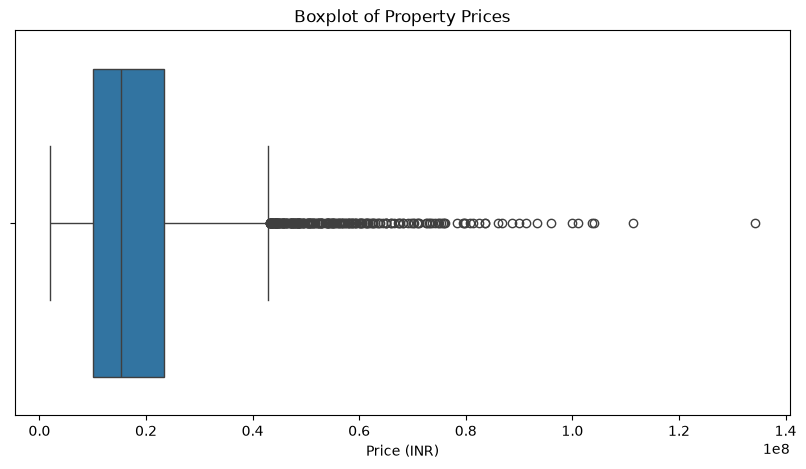

In [36]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=train_data['Price_INR'])

plt.title('Boxplot of Property Prices')
plt.xlabel('Price (INR)')

plt.show()

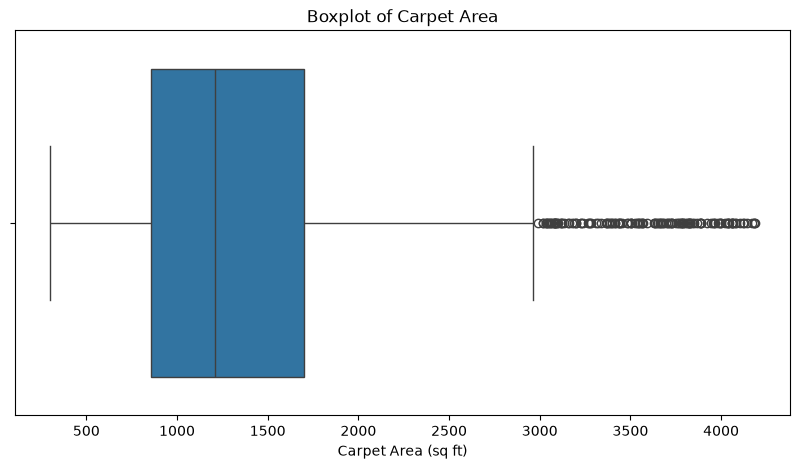

In [37]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=train_data['CarpetArea_sqft'])

plt.title('Boxplot of Carpet Area')
plt.xlabel('Carpet Area (sq ft)')

plt.show()

In [38]:
train_data[
    ['ListingID', 'City', 'PropertyType',
     'BHK', 'CarpetArea_sqft', 'Price_INR']
].sort_values(
    'Price_INR',
    ascending=False
).head(10)

,ListingID,City,PropertyType,BHK,CarpetArea_sqft,Price_INR
317,HP02300,MMR,Penthouse,6,4045,134200000
3826,HP01773,MMR,Penthouse,5,3827,111290000
3357,HP02101,MMR,Independent House,5,4172,104110000
25,HP01489,MMR,Penthouse,5,3482,103690000
2238,HP02307,MMR,Independent House,6,4181,101120000
1733,HP00929,MMR,Penthouse,5,2853,99980000
4283,HP00072,MMR,Independent House,5,3831,96060000
3538,HP02179,MMR,Penthouse,5,3921,93340000
1305,HP00554,MMR,Villa,5,3380,91370000
1928,HP01569,MMR,Villa,5,3094,89950000


In [39]:
train_data[
    ['ListingID', 'City', 'PropertyType',
     'BHK', 'CarpetArea_sqft', 'Price_INR']
].sort_values(
    'CarpetArea_sqft',
    ascending=False
).head(10)

,ListingID,City,PropertyType,BHK,CarpetArea_sqft,Price_INR
4058,HP00135,Chennai,Penthouse,5,4185,62630000
2238,HP02307,MMR,Independent House,6,4181,101120000
902,HP00272,Bengaluru,Villa,5,4179,62320000
3357,HP02101,MMR,Independent House,5,4172,104110000
861,HP00153,Delhi NCR,Independent House,5,4143,47920000
2587,HP01231,Ahmedabad,Independent House,5,4125,28870000
1652,HP02116,Kolkata,Independent House,6,4121,43310000
207,HP01813,Chennai,Independent House,5,4106,60120000
592,HP01243,Hyderabad,Penthouse,5,4085,57730000
1638,HP01306,Chennai,Penthouse,5,4074,75960000


In [40]:
clean_data = train_data.copy()

In [41]:
print("Clean dataset shape:", clean_data.shape)

Clean dataset shape: (4728, 24)


## 9. Feature Engineering

Feature engineering creates meaningful new variables from existing
data to improve analysis and extract additional business insights.

For this project, we will create:
- Price in Lakhs for easier interpretation
- Price per square foot for comparing properties of different sizes
- Area difference between built-up and carpet area

In [42]:
clean_data['Price_Lakhs'] = (
    clean_data['Price_INR'] / 100000
)

In [43]:
clean_data[
    ['Price_INR', 'Price_Lakhs']
].head()

,Price_INR,Price_Lakhs
0,17770000,177.7
1,7130000,71.3
2,5920000,59.2
3,19140000,191.4
4,20300000,203.0


In [44]:
clean_data['Price_per_sqft'] = (
    clean_data['Price_INR'] /
    clean_data['CarpetArea_sqft']
)

In [45]:
clean_data[
    ['Price_INR',
     'CarpetArea_sqft',
     'Price_per_sqft']
].head()

,Price_INR,CarpetArea_sqft,Price_per_sqft
0,17770000,1089,16317.722681
1,7130000,771,9247.730220
2,5920000,611,9689.034370
3,19140000,817,23427.172583
4,20300000,1778,11417.322835


In [46]:
clean_data['BuiltUp_Carpet_Difference'] = (
    clean_data['BuiltUpArea_sqft'] -
    clean_data['CarpetArea_sqft']
)

In [47]:
clean_data[
    ['BuiltUpArea_sqft',
     'CarpetArea_sqft',
     'BuiltUp_Carpet_Difference']
].head()

,BuiltUpArea_sqft,CarpetArea_sqft,BuiltUp_Carpet_Difference
0,1299,1089,210
1,870,771,99
2,710,611,99
3,952,817,135
4,2176,1778,398


In [48]:
clean_data['BuiltUp_Carpet_Ratio'] = (
    clean_data['BuiltUpArea_sqft'] /
    clean_data['CarpetArea_sqft']
)

In [49]:
clean_data[
    ['BuiltUpArea_sqft',
     'CarpetArea_sqft',
     'BuiltUp_Carpet_Ratio']
].head()

,BuiltUpArea_sqft,CarpetArea_sqft,BuiltUp_Carpet_Ratio
0,1299,1089,1.192837
1,870,771,1.128405
2,710,611,1.162029
3,952,817,1.165239
4,2176,1778,1.223847


In [50]:
print(
    clean_data[
        [
            'Price_Lakhs',
            'Price_per_sqft',
            'BuiltUp_Carpet_Difference',
            'BuiltUp_Carpet_Ratio'
        ]
    ].describe()
)

       Price_Lakhs  Price_per_sqft  BuiltUp_Carpet_Difference  \
count  4728.000000     4728.000000                4728.000000   
mean    185.341540    13580.532518                 229.903765   
std     127.660288     4822.948205                 151.725240   
min      20.000000     5283.018868                  32.000000   
25%     100.700000    10812.687886                 124.000000   
50%     153.100000    12578.996626                 193.000000   
75%     233.300000    14886.318668                 291.000000   
max    1342.000000    41251.564456                1193.000000   

       BuiltUp_Carpet_Ratio  
count           4728.000000  
mean               1.167532  
std                0.047259  
min                1.098930  
25%                1.130898  
50%                1.162748  
75%                1.197451  
max                1.350269  


In [51]:
print(
    "Invalid Price per sq.ft.:",
    (
        (clean_data['Price_per_sqft'] <= 0) |
        (~np.isfinite(clean_data['Price_per_sqft']))
    ).sum()
)

Invalid Price per sq.ft.: 0


In [52]:
print(
    "Invalid Built-up/Carpet ratio:",
    (
        (clean_data['BuiltUp_Carpet_Ratio'] <= 0) |
        (~np.isfinite(clean_data['BuiltUp_Carpet_Ratio']))
    ).sum()
)

Invalid Built-up/Carpet ratio: 0


## 10. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution,
patterns, and characteristics of the real estate dataset.

In this stage, we analyze individual variables such as property price,
property area, BHK, property type, and city before studying relationships
between multiple variables.

The findings from EDA will later be used to create meaningful market
insights for the dashboard.

### 10.1 Property Price Distribution

The distribution of property prices helps us understand the typical
price range of properties and identify whether the market contains
high-value properties that create a skewed distribution.

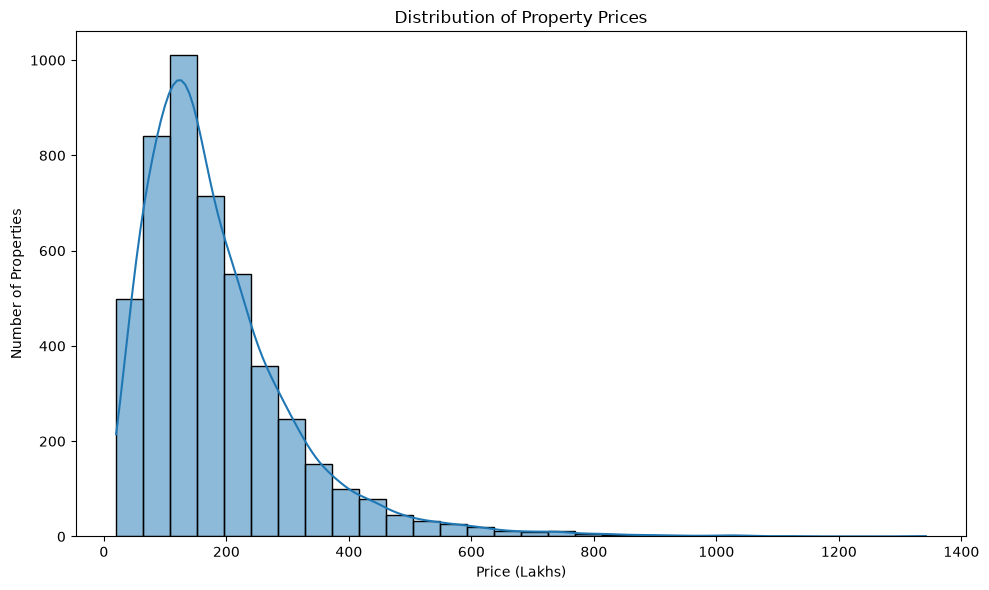

In [53]:
plt.figure(figsize=(10, 6))

sns.histplot(
    clean_data['Price_Lakhs'],
    bins=30,
    kde=True
)

plt.title('Distribution of Property Prices')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Number of Properties')

plt.tight_layout()
plt.show()

In [54]:
print("Price Statistics:")
print(clean_data['Price_Lakhs'].describe())

Price Statistics:
count    4728.000000
mean      185.341540
std       127.660288
min        20.000000
25%       100.700000
50%       153.100000
75%       233.300000
max      1342.000000
Name: Price_Lakhs, dtype: float64


### 10.2 Property Area Distribution

Property size is an important factor in real estate.
The distribution of carpet area helps us understand the size of
properties available in the market.

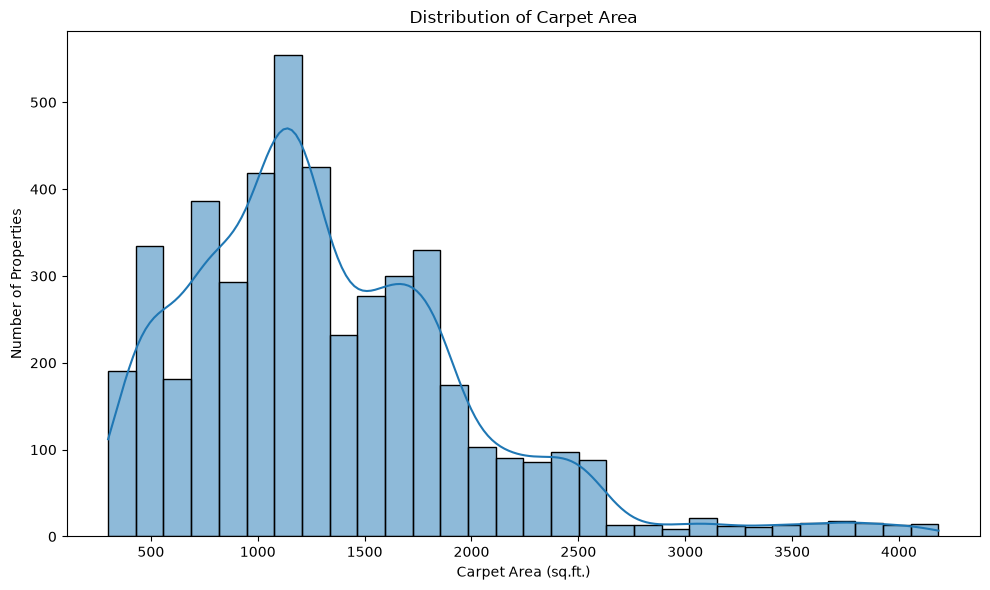

In [55]:
plt.figure(figsize=(10, 6))

sns.histplot(
    clean_data['CarpetArea_sqft'],
    bins=30,
    kde=True
)

plt.title('Distribution of Carpet Area')
plt.xlabel('Carpet Area (sq.ft.)')
plt.ylabel('Number of Properties')

plt.tight_layout()
plt.show()

### 10.3 BHK Distribution

This analysis shows which property configurations are most common
in the dataset and helps identify the dominant housing segment.

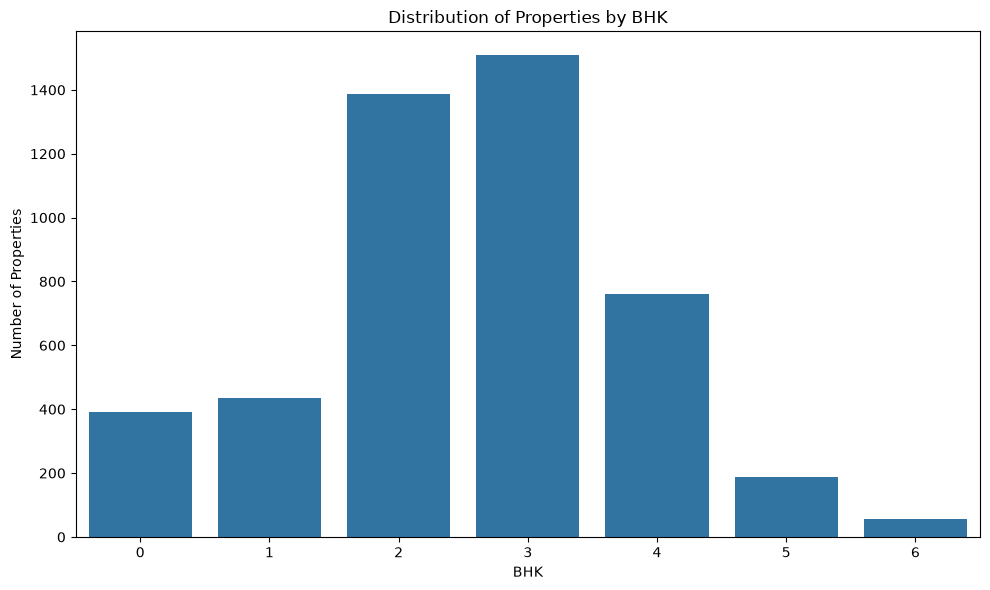

In [56]:
bhk_counts = clean_data['BHK'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=bhk_counts.index,
    y=bhk_counts.values
)

plt.title('Distribution of Properties by BHK')
plt.xlabel('BHK')
plt.ylabel('Number of Properties')

plt.tight_layout()
plt.show()

### 10.4 Property Type Distribution

Different property types represent different segments of the real
estate market. This analysis identifies the most frequently listed
property types in the dataset.

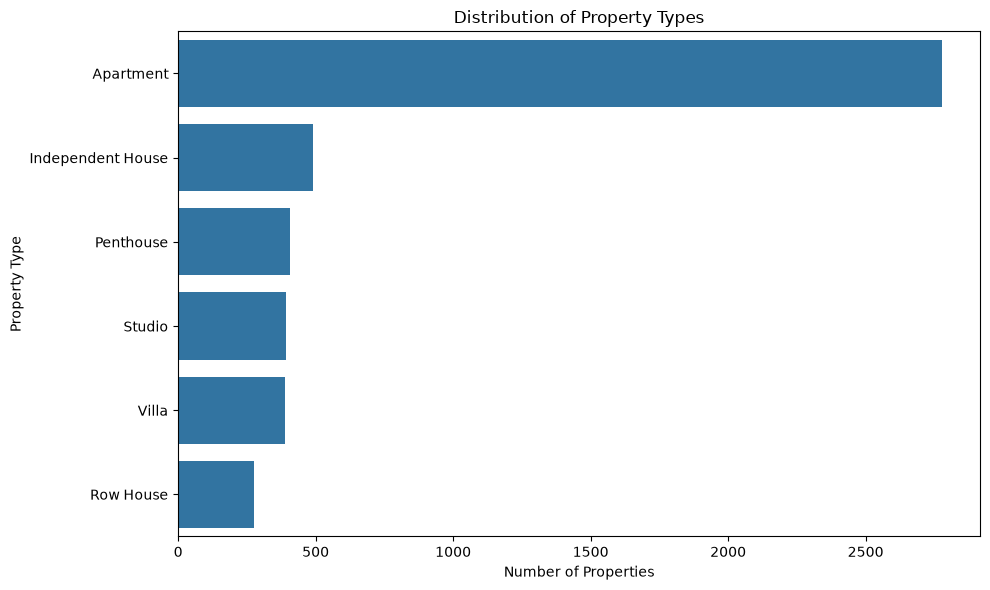

In [57]:
property_counts = (
    clean_data['PropertyType']
    .value_counts()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=property_counts.values,
    y=property_counts.index
)

plt.title('Distribution of Property Types')
plt.xlabel('Number of Properties')
plt.ylabel('Property Type')

plt.tight_layout()
plt.show()

### 10.5 Property Distribution by City

The dataset contains properties from multiple cities.
Understanding the number of listings from each city is important before
comparing their market prices.

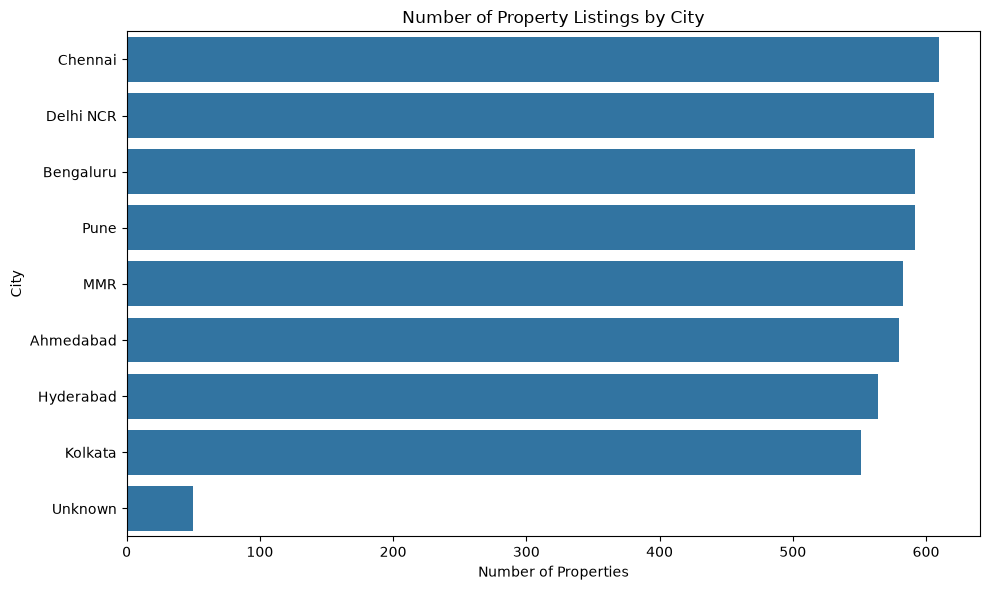

In [58]:
city_counts = (
    clean_data['City']
    .value_counts()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_counts.values,
    y=city_counts.index
)

plt.title('Number of Property Listings by City')
plt.xlabel('Number of Properties')
plt.ylabel('City')

plt.tight_layout()
plt.show()

### 10.6 Furnishing Status Distribution

Furnishing status can influence property demand and pricing.
This analysis shows the proportion of furnished, semi-furnished,
unfurnished, and unspecified properties in the dataset.

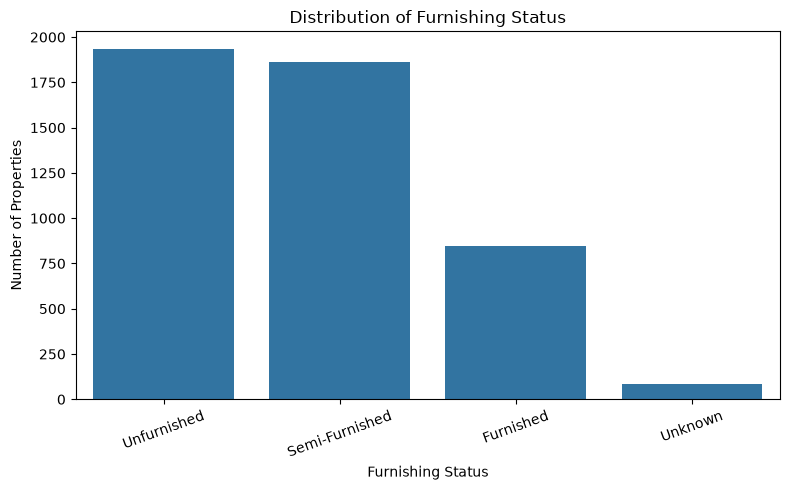

In [59]:
furnishing_counts = (
    clean_data['Furnishing']
    .value_counts()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=furnishing_counts.index,
    y=furnishing_counts.values
)

plt.title('Distribution of Furnishing Status')
plt.xlabel('Furnishing Status')
plt.ylabel('Number of Properties')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [60]:
print("===== REAL ESTATE MARKET SUMMARY =====")

print(
    "Total Properties:",
    len(clean_data)
)

print(
    "Average Price:",
    round(clean_data['Price_Lakhs'].mean(), 2),
    "Lakhs"
)

print(
    "Median Price:",
    round(clean_data['Price_Lakhs'].median(), 2),
    "Lakhs"
)

print(
    "Average Carpet Area:",
    round(clean_data['CarpetArea_sqft'].mean(), 2),
    "sq.ft."
)

print(
    "Average Price per Sq.Ft.:",
    round(clean_data['Price_per_sqft'].mean(), 2)
)

print(
    "Most Common BHK:",
    clean_data['BHK'].mode()[0]
)

print(
    "Most Common Property Type:",
    clean_data['PropertyType'].mode()[0]
)

print(
    "Most Common City:",
    clean_data['City'].mode()[0]
)

===== REAL ESTATE MARKET SUMMARY =====
Total Properties: 4728
Average Price: 185.34 Lakhs
Median Price: 153.1 Lakhs
Average Carpet Area: 1333.16 sq.ft.
Average Price per Sq.Ft.: 13580.53
Most Common BHK: 3
Most Common Property Type: Apartment
Most Common City: Chennai


## 11. Bivariate Market Analysis

In this stage, we analyze relationships between property prices and
important real-estate characteristics.

The analysis focuses on:
- City and property price
- BHK and property price
- Property type and property price
- Carpet area and property price
- Furnishing status and property price
- Price per square foot across cities

These comparisons help identify differences between market segments
and locations.

### 11.1 Average Property Price by City

Comparing average property prices across cities helps identify
differences in the overall price levels of the markets represented
in the dataset.

In [61]:
city_price = (
    clean_data.groupby('City')
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Property_Count=('ListingID', 'count'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .sort_values(
        'Average_Price_Lakhs',
        ascending=False
    )
)

print(city_price)

           Average_Price_Lakhs  Median_Price_Lakhs  Property_Count  \
City                                                                 
MMR                 321.992453              281.30             583   
Unknown             202.086000              183.00              50   
Chennai             186.071803              160.50             610   
Bengaluru           185.135473              162.50             592   
Delhi NCR           183.805611              160.30             606   
Pune                183.062838              161.50             592   
Hyderabad           162.939007              141.95             564   
Kolkata             153.742650              134.10             551   
Ahmedabad           101.716724               89.80             580   

           Average_Price_per_sqft  
City                               
MMR                  23787.027962  
Unknown              13910.216952  
Chennai              13218.636817  
Bengaluru            13837.254861  
Delhi NCR    

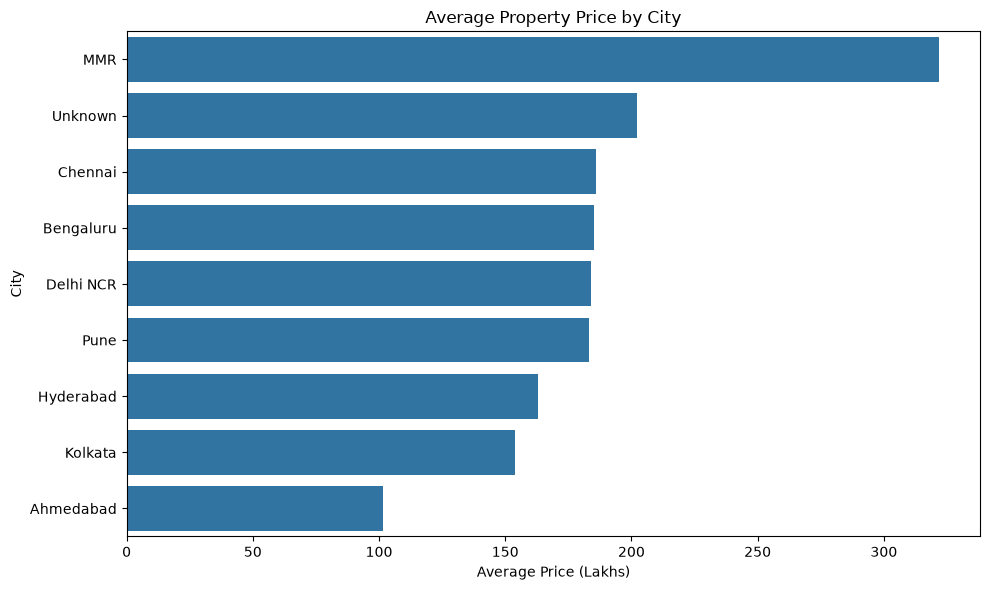

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=city_price.reset_index(),
    x='Average_Price_Lakhs',
    y='City'
)

plt.title('Average Property Price by City')
plt.xlabel('Average Price (Lakhs)')
plt.ylabel('City')

plt.tight_layout()
plt.show()

### 11.2 Property Price by BHK

This analysis examines how property prices vary with the number of
bedrooms. It helps identify the price differences between different
housing configurations.

In [63]:
bhk_price = (
    clean_data.groupby('BHK')
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Property_Count=('ListingID', 'count'),
        Average_Area=('CarpetArea_sqft', 'mean')
    )
    .sort_index()
)

print(bhk_price)

     Average_Price_Lakhs  Median_Price_Lakhs  Property_Count  Average_Area
BHK                                                                       
0              50.911480               47.85             392    431.349490
1              81.567281               76.20             434    620.993088
2             133.203102              123.05            1386   1002.723665
3             200.184483              187.55            1508   1451.354111
4             289.315617              269.90             762   2020.070866
5             460.084656              427.80             189   3024.968254
6             474.124561              433.10              57   3072.842105


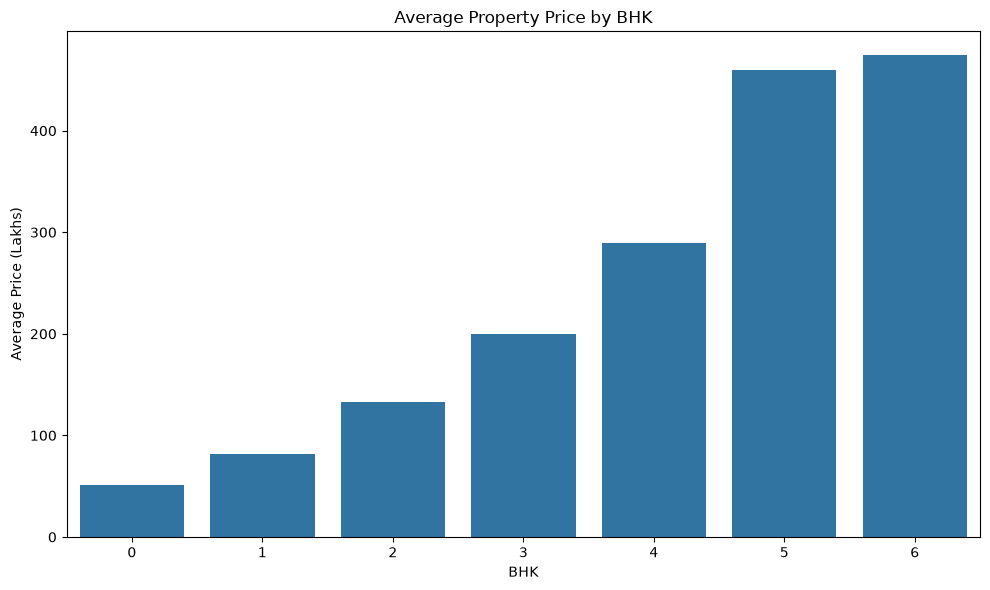

In [64]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=bhk_price.reset_index(),
    x='BHK',
    y='Average_Price_Lakhs'
)

plt.title('Average Property Price by BHK')
plt.xlabel('BHK')
plt.ylabel('Average Price (Lakhs)')

plt.tight_layout()
plt.show()

### 11.3 Property Type and Price Analysis

Different property types can have substantially different price
levels. This analysis compares the average and median prices of the
property types available in the dataset.

In [65]:
property_price = (
    clean_data.groupby('PropertyType')
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Property_Count=('ListingID', 'count'),
        Average_Area=('CarpetArea_sqft', 'mean')
    )
    .sort_values(
        'Average_Price_Lakhs',
        ascending=False
    )
)

print(property_price)

                   Average_Price_Lakhs  Median_Price_Lakhs  Property_Count  \
PropertyType                                                                 
Penthouse                   340.771358              300.20             405   
Villa                       294.214212              267.10             387   
Independent House           248.740204              215.80             490   
Row House                   167.915162              149.70             277   
Apartment                   157.028808              139.20            2777   
Studio                       50.911480               47.85             392   

                   Average_Area  
PropertyType                     
Penthouse           1912.172840  
Villa               1900.875969  
Independent House   1920.653061  
Row House           1203.397112  
Apartment           1206.180411  
Studio               431.349490  


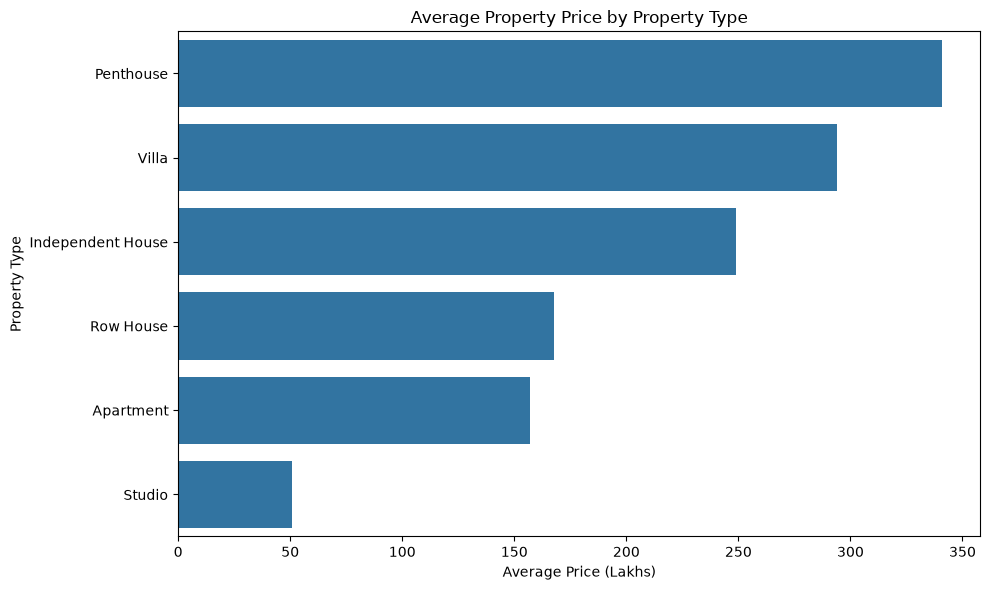

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=property_price.reset_index(),
    x='Average_Price_Lakhs',
    y='PropertyType'
)

plt.title('Average Property Price by Property Type')
plt.xlabel('Average Price (Lakhs)')
plt.ylabel('Property Type')

plt.tight_layout()
plt.show()

### 11.4 Relationship Between Property Area and Price

This analysis investigates whether larger properties generally have
higher prices.

A scatter plot is used because both variables are continuous numerical
variables.

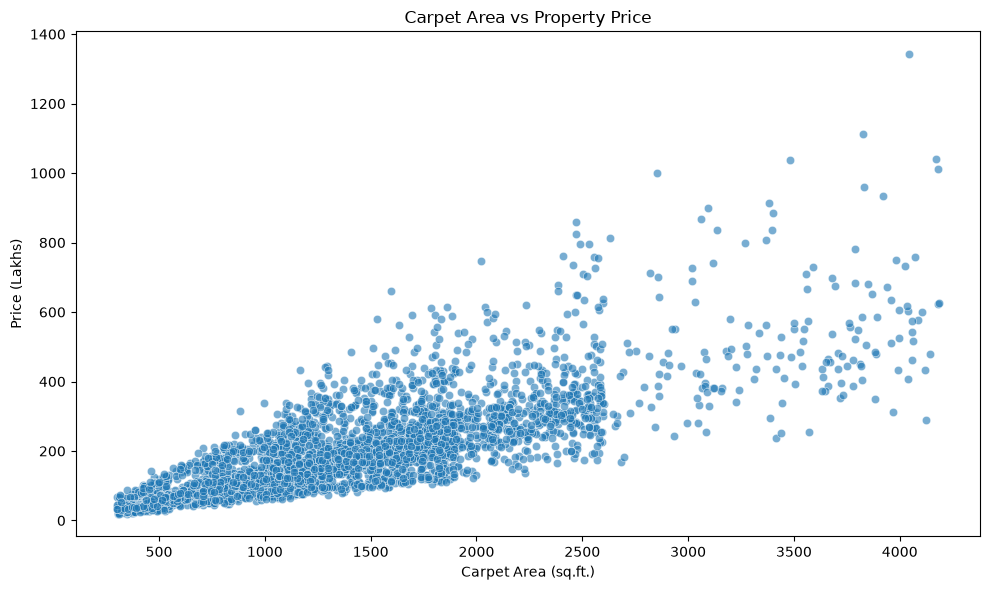

In [67]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean_data,
    x='CarpetArea_sqft',
    y='Price_Lakhs',
    alpha=0.6
)

plt.title('Carpet Area vs Property Price')
plt.xlabel('Carpet Area (sq.ft.)')
plt.ylabel('Price (Lakhs)')

plt.tight_layout()
plt.show()

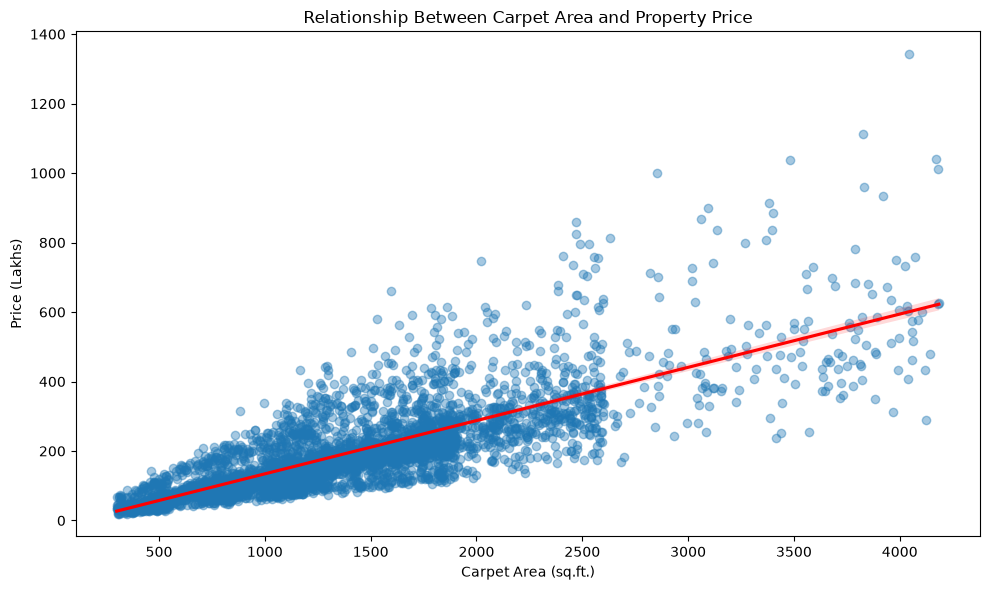

In [68]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=clean_data,
    x='CarpetArea_sqft',
    y='Price_Lakhs',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between Carpet Area and Property Price')
plt.xlabel('Carpet Area (sq.ft.)')
plt.ylabel('Price (Lakhs)')

plt.tight_layout()
plt.show()

### 11.5 Furnishing Status and Property Price

This analysis compares property prices across different furnishing
categories to determine whether furnished properties tend to have
different price levels from semi-furnished and unfurnished properties.

In [69]:
furnishing_price = (
    clean_data.groupby('Furnishing')
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Property_Count=('ListingID', 'count')
    )
    .sort_values(
        'Average_Price_Lakhs',
        ascending=False
    )
)

print(furnishing_price)

                Average_Price_Lakhs  Median_Price_Lakhs  Property_Count
Furnishing                                                             
Furnished                199.527091               166.2             849
Unknown                  194.640964               172.1              83
Semi-Furnished           189.716335               155.7            1861
Unfurnished              174.511111               145.3            1935


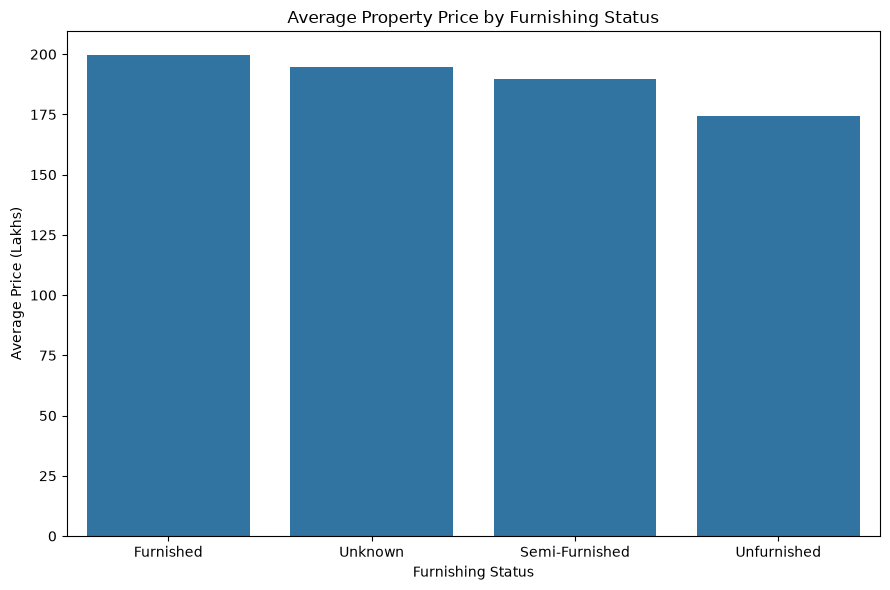

In [70]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=furnishing_price.reset_index(),
    x='Furnishing',
    y='Average_Price_Lakhs'
)

plt.title('Average Property Price by Furnishing Status')
plt.xlabel('Furnishing Status')
plt.ylabel('Average Price (Lakhs)')

plt.tight_layout()
plt.show()

### 11.6 Price per Square Foot by City

Total property price alone cannot be used to fairly compare different
cities because properties have different sizes.

Price per square foot provides a normalized measure of property value
and allows a more meaningful comparison between city-level markets.

In [71]:
city_ppsf = (
    clean_data.groupby('City')
    .agg(
        Average_Price_per_sqft=('Price_per_sqft', 'mean'),
        Median_Price_per_sqft=('Price_per_sqft', 'median'),
        Property_Count=('ListingID', 'count')
    )
    .sort_values(
        'Average_Price_per_sqft',
        ascending=False
    )
)

print(city_ppsf)

           Average_Price_per_sqft  Median_Price_per_sqft  Property_Count
City                                                                    
MMR                  23787.027962           23181.542198             583
Unknown              13910.216952           13525.474296              50
Bengaluru            13837.254861           13380.258881             592
Delhi NCR            13603.920954           13222.388714             606
Chennai              13218.636817           12878.464434             610
Pune                 13089.623170           12826.895938             592
Hyderabad            11786.453587           11469.330348             564
Kolkata              11451.355847           11179.487179             551
Ahmedabad             7655.338534            7481.794890             580


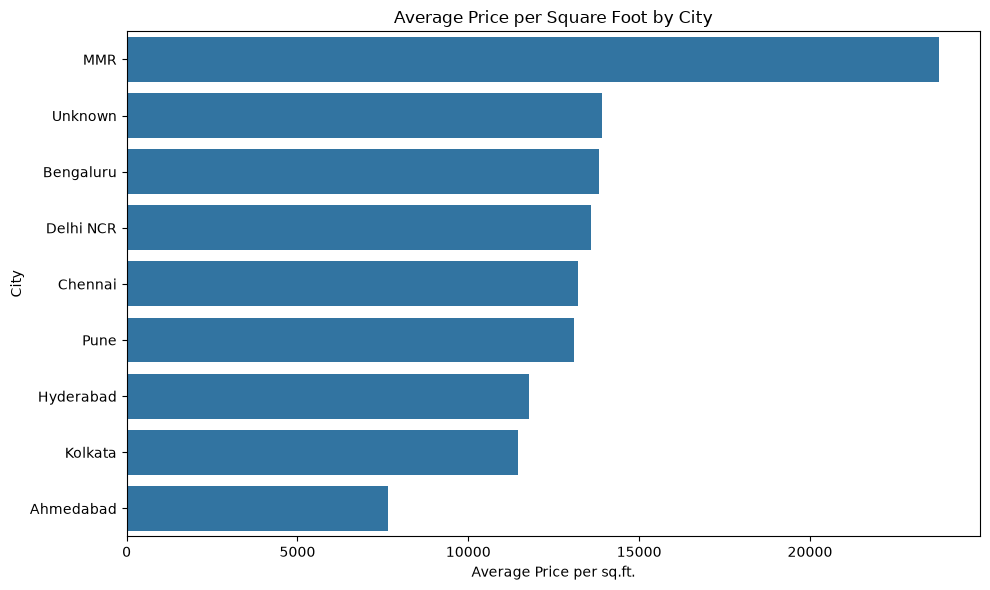

In [72]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=city_ppsf.reset_index(),
    x='Average_Price_per_sqft',
    y='City'
)

plt.title('Average Price per Square Foot by City')
plt.xlabel('Average Price per sq.ft.')
plt.ylabel('City')

plt.tight_layout()
plt.show()

### 11.7 City and Property Type Comparison

A city may contain several types of properties with different price
levels. A grouped analysis helps identify how property type affects
prices within different city markets.

In [73]:
city_property_analysis = (
    clean_data.groupby(
        ['City', 'PropertyType']
    )
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Property_Count=('ListingID', 'count'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

print(city_property_analysis.head(20))

         City       PropertyType  Average_Price_Lakhs  Property_Count  \
0   Ahmedabad          Apartment            88.651032             339   
1   Ahmedabad  Independent House           129.186154              65   
2   Ahmedabad          Penthouse           205.105128              39   
3   Ahmedabad          Row House            97.981818              44   
4   Ahmedabad             Studio            28.156604              53   
5   Ahmedabad              Villa           168.582500              40   
6   Bengaluru          Apartment           152.310746             335   
7   Bengaluru  Independent House           249.467742              62   
8   Bengaluru          Penthouse           341.474138              58   
9   Bengaluru          Row House           170.333333              36   
10  Bengaluru             Studio            49.409804              51   
11  Bengaluru              Villa           293.034000              50   
12    Chennai          Apartment           155.6138

In [74]:
city_price.to_csv(
    'city_price_analysis.csv'
)

bhk_price.to_csv(
    'bhk_price_analysis.csv'
)

property_price.to_csv(
    'property_type_analysis.csv'
)

city_ppsf.to_csv(
    'city_price_per_sqft_analysis.csv'
)

## 12. Multivariate Exploratory Data Analysis

Multivariate analysis examines relationships among multiple variables
simultaneously.

In this stage, we analyze correlations between numerical variables and
investigate how property price is associated with area, BHK, bathrooms,
property age, amenities, and other measurable characteristics.

The objective is to identify important patterns and relationships that
can support the later market analysis and machine-learning stages.

In [75]:
numeric_data = clean_data.select_dtypes(
    include=np.number
)

print("Numerical features:")
print(numeric_data.columns.tolist())

Numerical features:
['BHK', 'Bathrooms', 'Balconies', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'YearBuilt', 'AgeYears', 'AmenitiesCount', 'Latitude', 'Longitude', 'Price_INR', 'Price_Lakhs', 'Price_per_sqft', 'BuiltUp_Carpet_Difference', 'BuiltUp_Carpet_Ratio']


In [76]:
price_correlation = (
    numeric_data.corr()['Price_INR']
    .sort_values(ascending=False)
)

print("Correlation with Property Price:")
print(price_correlation)

Correlation with Property Price:
Price_INR                    1.000000
Price_Lakhs                  1.000000
SuperBuiltUpArea_sqft        0.820529
BuiltUpArea_sqft             0.815033
CarpetArea_sqft              0.808819
BuiltUp_Carpet_Difference    0.757523
BHK                          0.716417
Bathrooms                    0.672803
Price_per_sqft               0.627540
BuiltUp_Carpet_Ratio         0.255814
Balconies                    0.130833
YearBuilt                    0.074848
TotalFloors                  0.002027
Floor                       -0.004730
AmenitiesCount              -0.020305
AgeYears                    -0.075929
Latitude                    -0.077182
Longitude                   -0.112920
Name: Price_INR, dtype: float64


### 12.1 Correlation Matrix

The correlation matrix shows the strength and direction of linear
relationships between numerical variables.

It helps identify variables that may be associated with property price
and also helps detect highly correlated features.

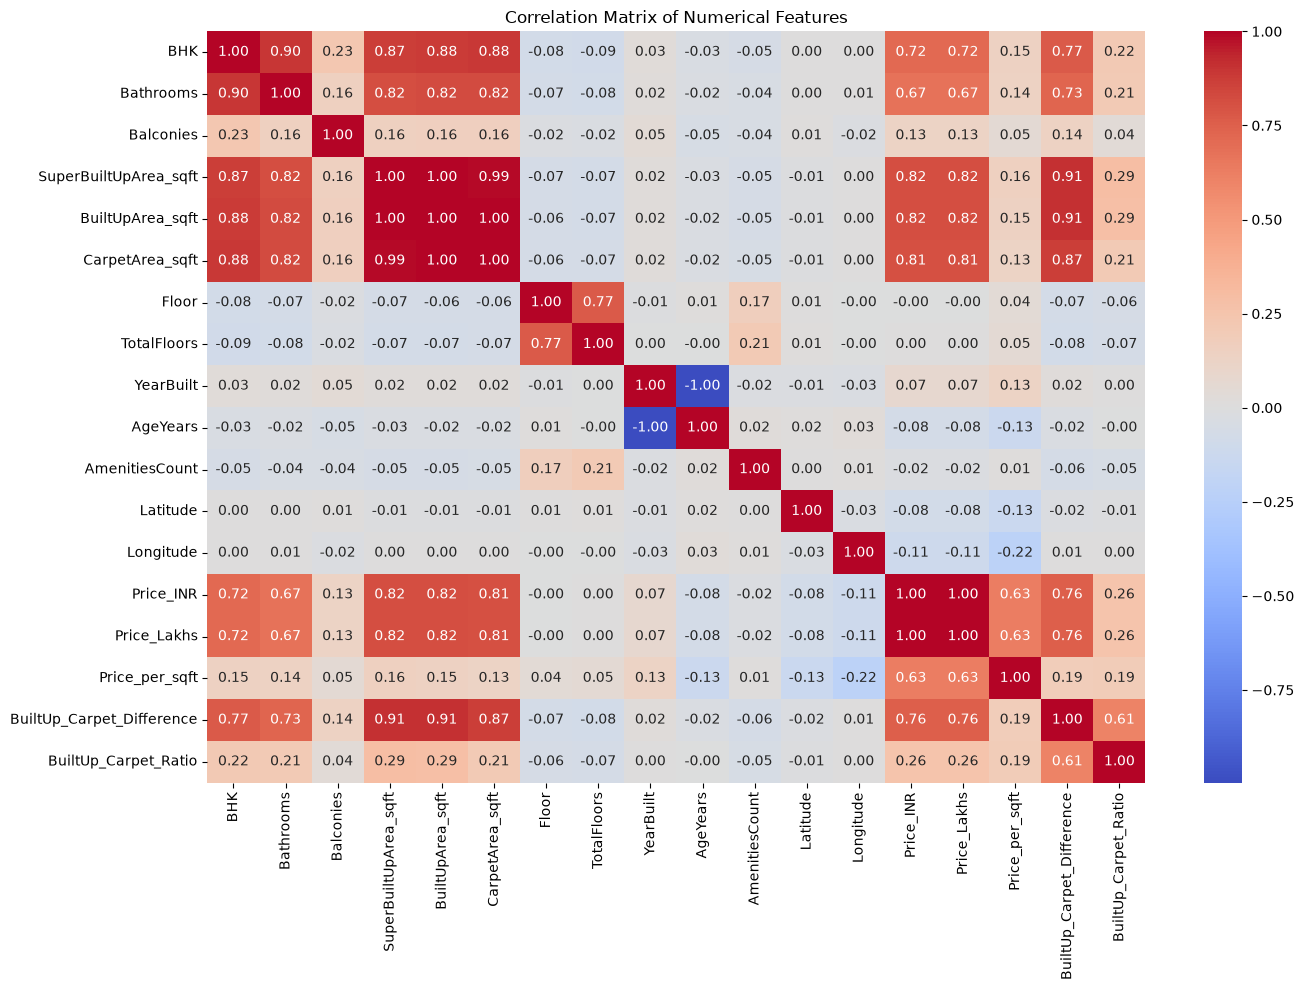

In [77]:
plt.figure(figsize=(14, 10))

correlation_matrix = numeric_data.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

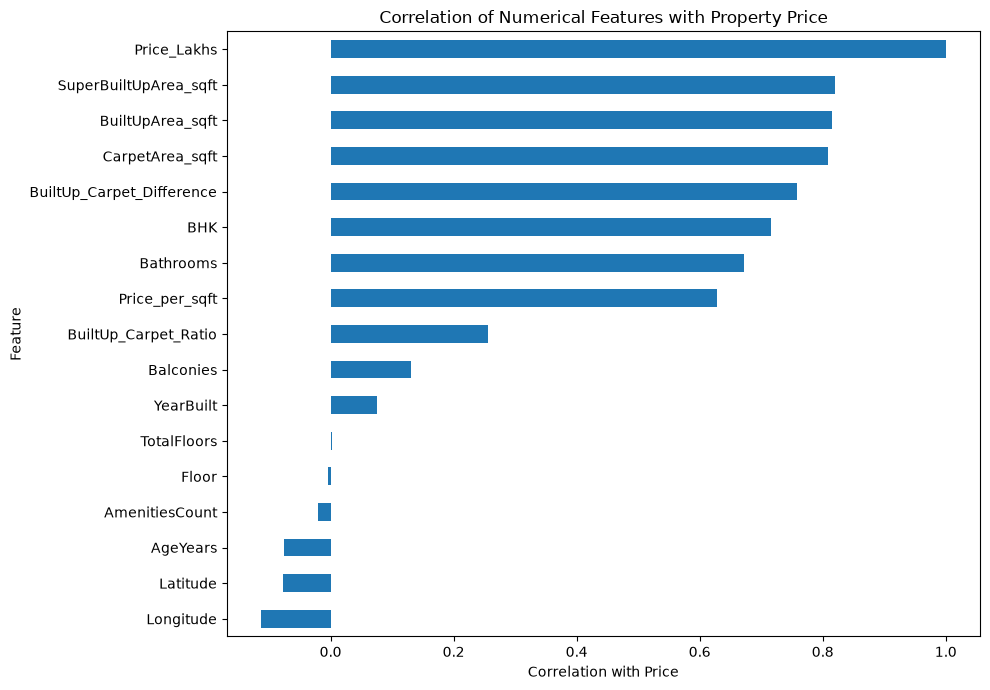

In [78]:
price_corr = (
    numeric_data.corr()['Price_INR']
    .drop('Price_INR')
    .sort_values()
)

plt.figure(figsize=(10, 7))

price_corr.plot(kind='barh')

plt.title('Correlation of Numerical Features with Property Price')
plt.xlabel('Correlation with Price')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

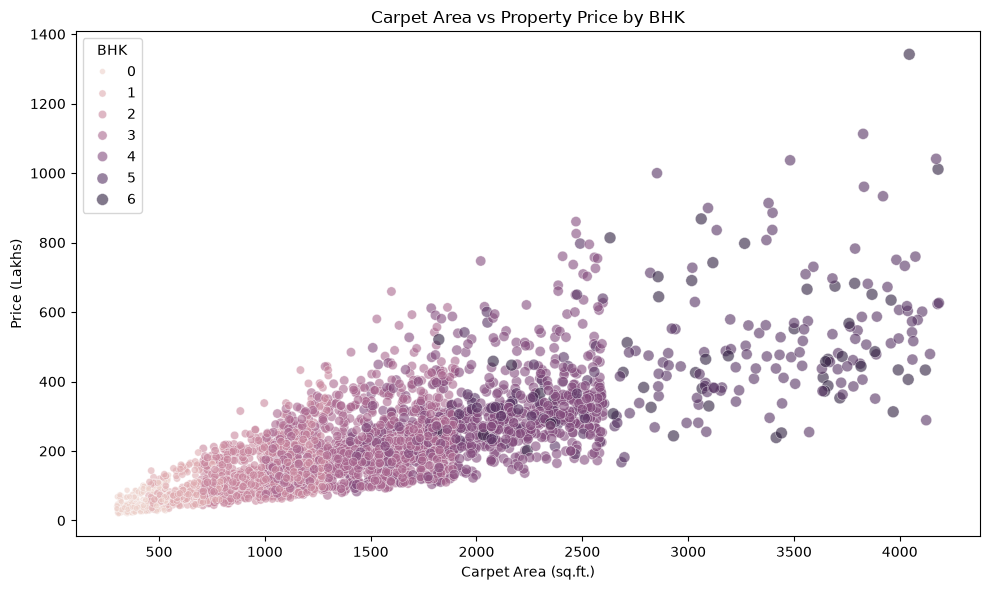

In [79]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean_data,
    x='CarpetArea_sqft',
    y='Price_Lakhs',
    hue='BHK',
    size='BHK',
    alpha=0.6
)

plt.title('Carpet Area vs Property Price by BHK')
plt.xlabel('Carpet Area (sq.ft.)')
plt.ylabel('Price (Lakhs)')

plt.tight_layout()
plt.show()

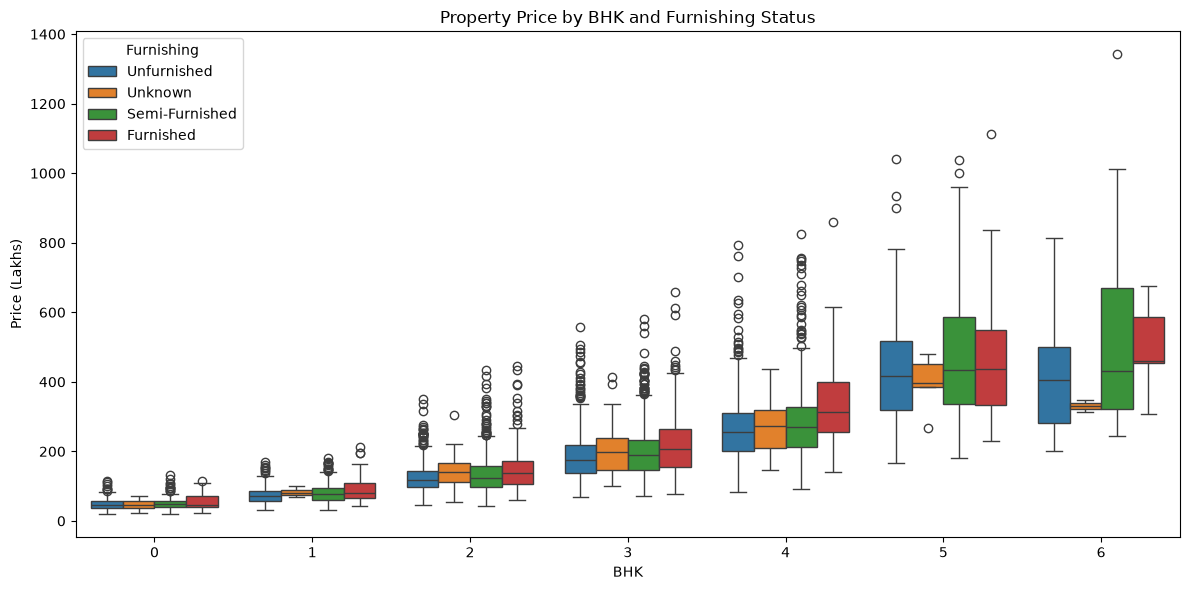

In [80]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=clean_data,
    x='BHK',
    y='Price_Lakhs',
    hue='Furnishing'
)

plt.title('Property Price by BHK and Furnishing Status')
plt.xlabel('BHK')
plt.ylabel('Price (Lakhs)')

plt.tight_layout()
plt.show()

In [81]:
property_ppsf = (
    clean_data.groupby('PropertyType')
    .agg(
        Average_Price_per_sqft=('Price_per_sqft', 'mean'),
        Median_Price_per_sqft=('Price_per_sqft', 'median'),
        Property_Count=('ListingID', 'count')
    )
    .sort_values(
        'Average_Price_per_sqft',
        ascending=False
    )
)

print(property_ppsf)

                   Average_Price_per_sqft  Median_Price_per_sqft  \
PropertyType                                                       
Penthouse                    17763.493256           16678.141136   
Villa                        15557.724472           14891.122278   
Row House                    14151.833685           13598.173516   
Apartment                    13009.401253           12163.644032   
Independent House            12878.448300           12126.874852   
Studio                       11826.782468           10989.048102   

                   Property_Count  
PropertyType                       
Penthouse                     405  
Villa                         387  
Row House                     277  
Apartment                    2777  
Independent House             490  
Studio                        392  


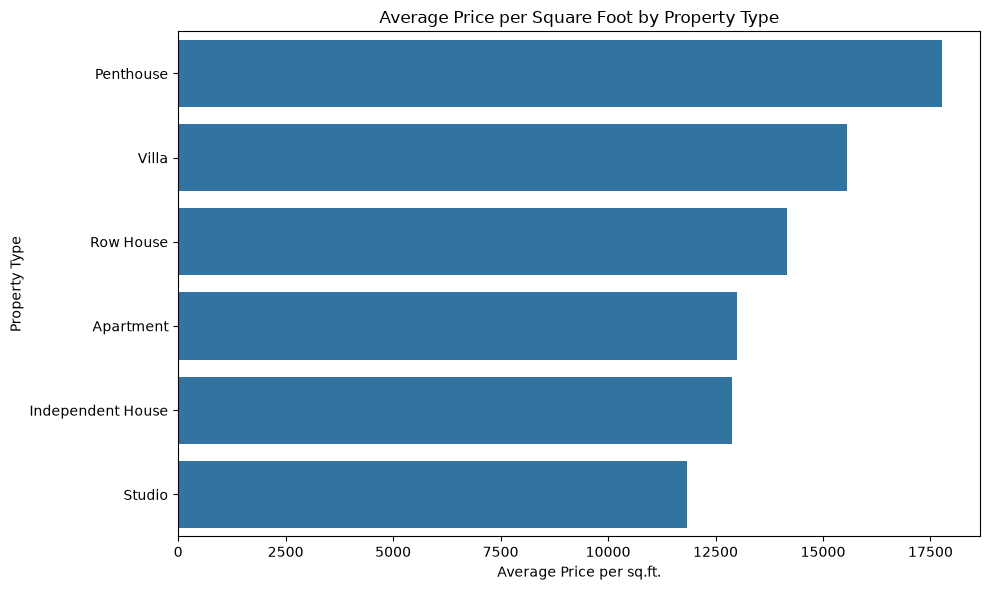

In [82]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=property_ppsf.reset_index(),
    x='Average_Price_per_sqft',
    y='PropertyType'
)

plt.title('Average Price per Square Foot by Property Type')
plt.xlabel('Average Price per sq.ft.')
plt.ylabel('Property Type')

plt.tight_layout()
plt.show()

In [83]:
city_bhk_analysis = (
    clean_data.groupby(['City', 'BHK'])
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean'),
        Property_Count=('ListingID', 'count')
    )
    .reset_index()
)

print(city_bhk_analysis.head(20))

         City  BHK  Average_Price_Lakhs  Median_Price_Lakhs  \
0   Ahmedabad    0            28.156604               27.50   
1   Ahmedabad    1            46.236735               44.10   
2   Ahmedabad    2            75.250000               74.85   
3   Ahmedabad    3           112.790857              112.10   
4   Ahmedabad    4           160.522581              156.90   
5   Ahmedabad    5           270.635294              255.40   
6   Ahmedabad    6           281.928571              252.00   
7   Bengaluru    0            49.409804               48.20   
8   Bengaluru    1            84.419672               83.00   
9   Bengaluru    2           133.346154              128.20   
10  Bengaluru    3           204.959091              204.30   
11  Bengaluru    4           307.084706              302.30   
12  Bengaluru    5           447.054545              432.65   
13  Bengaluru    6           479.316667              452.25   
14    Chennai    0            50.157377               4

In [84]:
city_bhk_pivot = clean_data.pivot_table(
    values='Price_Lakhs',
    index='City',
    columns='BHK',
    aggfunc='mean'
)

print(city_bhk_pivot)

BHK                0           1           2           3           4  \
City                                                                   
Ahmedabad  28.156604   46.236735   75.250000  112.790857  160.522581   
Bengaluru  49.409804   84.419672  133.346154  204.959091  307.084706   
Chennai    50.157377   79.588000  130.739412  194.856989  293.624272   
Delhi NCR  50.826190   80.489091  135.087432  195.614500  288.469307   
Hyderabad  44.626316   70.146809  120.629379  169.664865  249.111494   
Kolkata    42.419048   67.207813  112.303750  170.115924  236.087000   
MMR        87.453571  144.701961  235.500000  345.402116  520.993023   
Pune       48.531250   79.809259  126.325806  195.204523  280.189899   
Unknown    46.500000   97.000000  137.831250  208.878947  277.925000   

BHK                 5           6  
City                               
Ahmedabad  270.635294  281.928571  
Bengaluru  447.054545  479.316667  
Chennai    454.577778  346.900000  
Delhi NCR  453.145455  625.

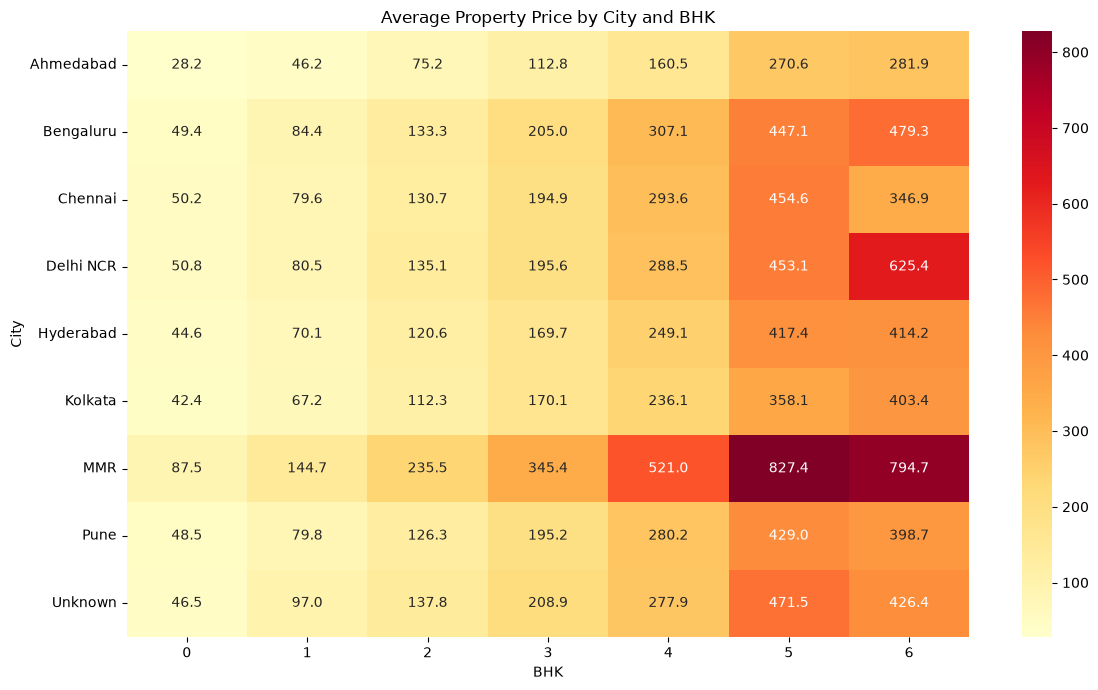

In [85]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    city_bhk_pivot,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)

plt.title('Average Property Price by City and BHK')
plt.xlabel('BHK')
plt.ylabel('City')

plt.tight_layout()
plt.show()

In [86]:
amenity_analysis = (
    clean_data.groupby('AmenitiesCount')
    .agg(
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Property_Count=('ListingID', 'count')
    )
    .reset_index()
)

print(amenity_analysis)

   AmenitiesCount  Average_Price_Lakhs  Median_Price_Lakhs  Property_Count
0               3           196.526923              165.00              52
1               4           204.479915              167.30             234
2               5           179.540550              149.20             545
3               6           190.475085              157.20             883
4               7           183.823789              150.00            1177
5               8           180.063163              151.20             980
6               9           187.487145              155.00             599
7              10           184.582960              158.50             223
8              11           169.467647              134.15              34
9              12           136.800000              136.80               1


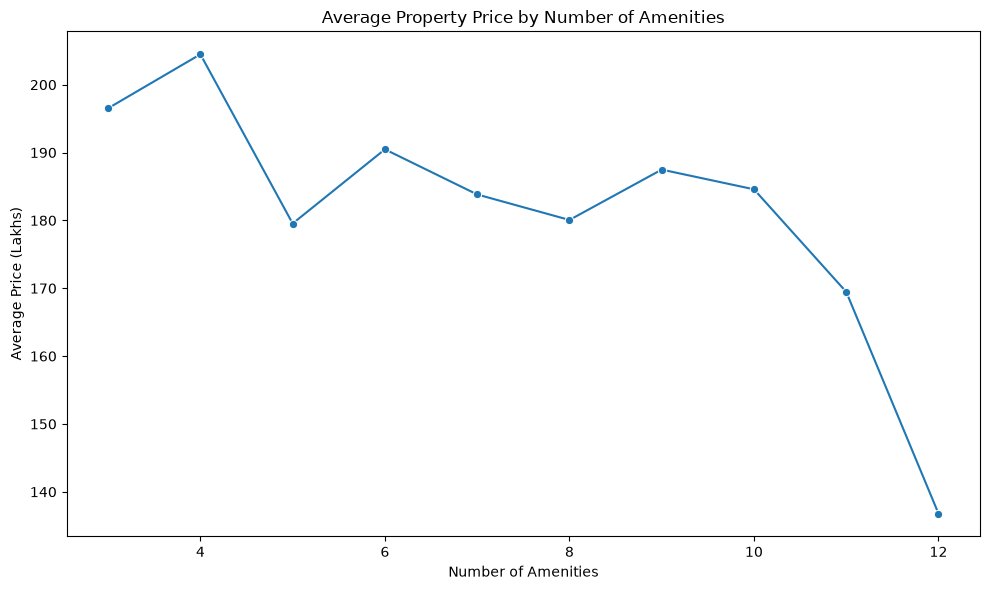

In [87]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=amenity_analysis,
    x='AmenitiesCount',
    y='Average_Price_Lakhs',
    marker='o'
)

plt.title('Average Property Price by Number of Amenities')
plt.xlabel('Number of Amenities')
plt.ylabel('Average Price (Lakhs)')

plt.tight_layout()
plt.show()

In [88]:
city_bhk_analysis.to_csv(
    'city_bhk_analysis.csv',
    index=False
)

property_ppsf.to_csv(
    'property_price_per_sqft_analysis.csv'
)

amenity_analysis.to_csv(
    'amenity_price_analysis.csv',
    index=False
)

## 13. Location and Market Segmentation Analysis

Location is one of the most important factors in real estate.

In this stage, properties are analyzed at both city and locality levels.
We compare property prices, price per square foot, property counts, and
average property sizes.

Locality-level rankings are interpreted together with listing counts so
that a locality with only a few observations is not automatically
treated as representative of the entire market.

In [89]:
city_market = (
    clean_data.groupby('City')
    .agg(
        Property_Count=('ListingID', 'count'),
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean'),
        Median_Price_per_sqft=('Price_per_sqft', 'median'),
        Average_Carpet_Area=('CarpetArea_sqft', 'mean'),
        Average_BHK=('BHK', 'mean')
    )
    .round(2)
    .sort_values('Average_Price_Lakhs', ascending=False)
)

print(city_market)

           Property_Count  Average_Price_Lakhs  Median_Price_Lakhs  \
City                                                                 
MMR                   583               321.99              281.30   
Unknown                50               202.09              183.00   
Chennai               610               186.07              160.50   
Bengaluru             592               185.14              162.50   
Delhi NCR             606               183.81              160.30   
Pune                  592               183.06              161.50   
Hyderabad             564               162.94              141.95   
Kolkata               551               153.74              134.10   
Ahmedabad             580               101.72               89.80   

           Average_Price_per_sqft  Median_Price_per_sqft  Average_Carpet_Area  \
City                                                                            
MMR                      23787.03               23181.54           

In [90]:
city_market['Price_Rank'] = (
    city_market['Average_Price_Lakhs']
    .rank(method='dense', ascending=False)
    .astype(int)
)

print(
    city_market[
        [
            'Price_Rank',
            'Property_Count',
            'Average_Price_Lakhs',
            'Median_Price_Lakhs'
        ]
    ].sort_values('Price_Rank')
)

           Price_Rank  Property_Count  Average_Price_Lakhs  Median_Price_Lakhs
City                                                                          
MMR                 1             583               321.99              281.30
Unknown             2              50               202.09              183.00
Chennai             3             610               186.07              160.50
Bengaluru           4             592               185.14              162.50
Delhi NCR           5             606               183.81              160.30
Pune                6             592               183.06              161.50
Hyderabad           7             564               162.94              141.95
Kolkata             8             551               153.74              134.10
Ahmedabad           9             580               101.72               89.80


In [91]:
city_market['Price_per_sqft_Rank'] = (
    city_market['Average_Price_per_sqft']
    .rank(method='dense', ascending=False)
    .astype(int)
)

print(
    city_market[
        [
            'Price_per_sqft_Rank',
            'Property_Count',
            'Average_Price_per_sqft',
            'Median_Price_per_sqft'
        ]
    ].sort_values('Price_per_sqft_Rank')
)

           Price_per_sqft_Rank  Property_Count  Average_Price_per_sqft  \
City                                                                     
MMR                          1             583                23787.03   
Unknown                      2              50                13910.22   
Bengaluru                    3             592                13837.25   
Delhi NCR                    4             606                13603.92   
Chennai                      5             610                13218.64   
Pune                         6             592                13089.62   
Hyderabad                    7             564                11786.45   
Kolkata                      8             551                11451.36   
Ahmedabad                    9             580                 7655.34   

           Median_Price_per_sqft  
City                              
MMR                     23181.54  
Unknown                 13525.47  
Bengaluru               13380.26  
Delhi NCR 

In [92]:
city_supply = (
    clean_data['City']
    .value_counts()
    .rename_axis('City')
    .reset_index(name='Property_Count')
)

print(city_supply)

        City  Property_Count
0    Chennai             610
1  Delhi NCR             606
2  Bengaluru             592
3       Pune             592
4        MMR             583
5  Ahmedabad             580
6  Hyderabad             564
7    Kolkata             551
8    Unknown              50


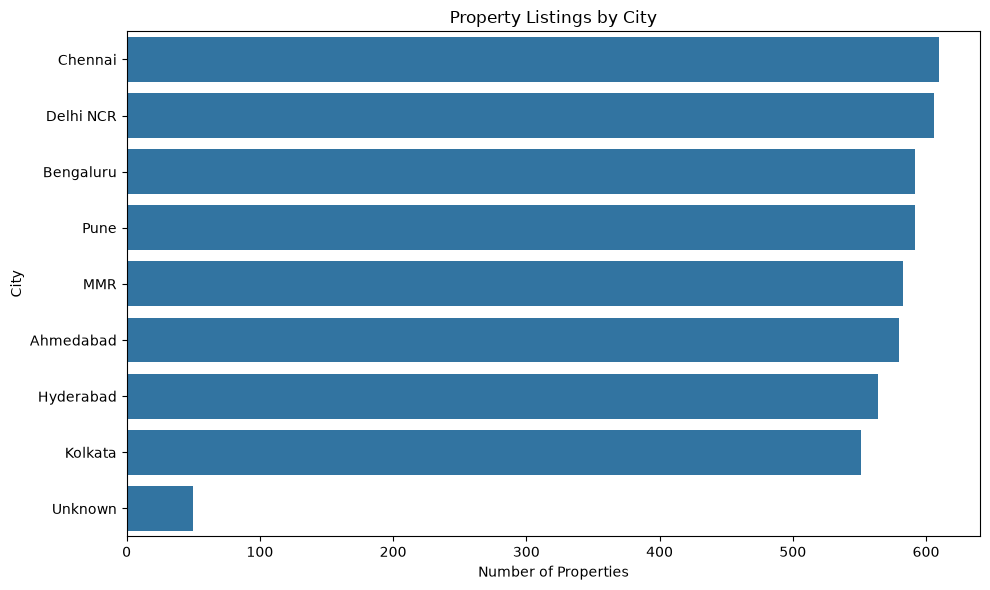

In [93]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=city_supply,
    x='Property_Count',
    y='City'
)

plt.title('Property Listings by City')
plt.xlabel('Number of Properties')
plt.ylabel('City')

plt.tight_layout()
plt.show()

In [94]:
locality_market = (
    clean_data.groupby(['City', 'Locality'])
    .agg(
        Property_Count=('ListingID', 'count'),
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean'),
        Median_Price_per_sqft=('Price_per_sqft', 'median'),
        Average_Carpet_Area=('CarpetArea_sqft', 'mean')
    )
    .round(2)
    .reset_index()
)

print(locality_market.head(20))

         City         Locality  Property_Count  Average_Price_Lakhs  \
0   Ahmedabad         Bodakdev              80               103.45   
1   Ahmedabad            Bopal              84                94.61   
2   Ahmedabad        Maninagar              82                98.21   
3   Ahmedabad    Prahlad Nagar              90                96.95   
4   Ahmedabad        Satellite              88               103.63   
5   Ahmedabad          Thaltej              67               120.40   
6   Ahmedabad          Unknown               6                90.67   
7   Ahmedabad        Vastrapur              83                99.58   
8   Bengaluru     Banashankari              56               182.40   
9   Bengaluru  Electronic City              53               191.29   
10  Bengaluru       HSR Layout              49               199.41   
11  Bengaluru           Hebbal              61               179.30   
12  Bengaluru      Indiranagar              53               180.83   
13  Be

In [95]:
locality_market = (
    clean_data.groupby(['City', 'Locality'])
    .agg(
        Property_Count=('ListingID', 'count'),
        Average_Price_Lakhs=('Price_Lakhs', 'mean'),
        Median_Price_Lakhs=('Price_Lakhs', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean'),
        Median_Price_per_sqft=('Price_per_sqft', 'median'),
        Average_Carpet_Area=('CarpetArea_sqft', 'mean')
    )
    .round(2)
    .reset_index()
)

print(locality_market.head(20))

         City         Locality  Property_Count  Average_Price_Lakhs  \
0   Ahmedabad         Bodakdev              80               103.45   
1   Ahmedabad            Bopal              84                94.61   
2   Ahmedabad        Maninagar              82                98.21   
3   Ahmedabad    Prahlad Nagar              90                96.95   
4   Ahmedabad        Satellite              88               103.63   
5   Ahmedabad          Thaltej              67               120.40   
6   Ahmedabad          Unknown               6                90.67   
7   Ahmedabad        Vastrapur              83                99.58   
8   Bengaluru     Banashankari              56               182.40   
9   Bengaluru  Electronic City              53               191.29   
10  Bengaluru       HSR Layout              49               199.41   
11  Bengaluru           Hebbal              61               179.30   
12  Bengaluru      Indiranagar              53               180.83   
13  Be

In [96]:
locality_reliable = locality_market[
    locality_market['Property_Count'] >= 5
].copy()

In [97]:
print(
    "Total localities:",
    locality_market.shape[0]
)

print(
    "Localities with at least 5 listings:",
    locality_reliable.shape[0]
)

Total localities: 100
Localities with at least 5 listings: 66


In [98]:
top_localities_ppsf = (
    locality_reliable
    .sort_values(
        'Average_Price_per_sqft',
        ascending=False
    )
    .head(10)
)

print(
    top_localities_ppsf[
        [
            'City',
            'Locality',
            'Property_Count',
            'Average_Price_per_sqft',
            'Average_Price_Lakhs'
        ]
    ]
)

         City              Locality  Property_Count  Average_Price_per_sqft  \
51        MMR           Bandra West              72                24457.47   
53        MMR                Mulund              67                24084.17   
57        MMR               Unknown              11                24059.33   
54        MMR  Navi Mumbai-Kharghar              66                24033.29   
55        MMR                 Powai              77                23947.20   
56        MMR            Thane West              68                23611.16   
50        MMR          Andheri West              74                23518.31   
58        MMR            Vile Parle              72                23466.22   
52        MMR         Goregaon East              76                23197.29   
13  Bengaluru           Koramangala              67                14081.02   

    Average_Price_Lakhs  
51               354.31  
53               310.88  
57               351.45  
54               323.33  


In [99]:
affordable_localities = (
    locality_reliable
    .sort_values(
        'Average_Price_per_sqft',
        ascending=True
    )
    .head(10)
)

print(
    affordable_localities[
        [
            'City',
            'Locality',
            'Property_Count',
            'Average_Price_per_sqft',
            'Average_Price_Lakhs'
        ]
    ]
)

         City       Locality  Property_Count  Average_Price_per_sqft  \
1   Ahmedabad          Bopal              84                 7443.89   
7   Ahmedabad      Vastrapur              83                 7488.04   
3   Ahmedabad  Prahlad Nagar              90                 7541.57   
0   Ahmedabad       Bodakdev              80                 7715.65   
4   Ahmedabad      Satellite              88                 7748.29   
2   Ahmedabad      Maninagar              82                 7799.49   
5   Ahmedabad        Thaltej              67                 7877.94   
6   Ahmedabad        Unknown               6                 8013.34   
45    Kolkata       New Town              79                11291.00   
47    Kolkata      Salt Lake              80                11309.89   

    Average_Price_Lakhs  
1                 94.61  
7                 99.58  
3                 96.95  
0                103.45  
4                103.63  
2                 98.21  
5                120.40  

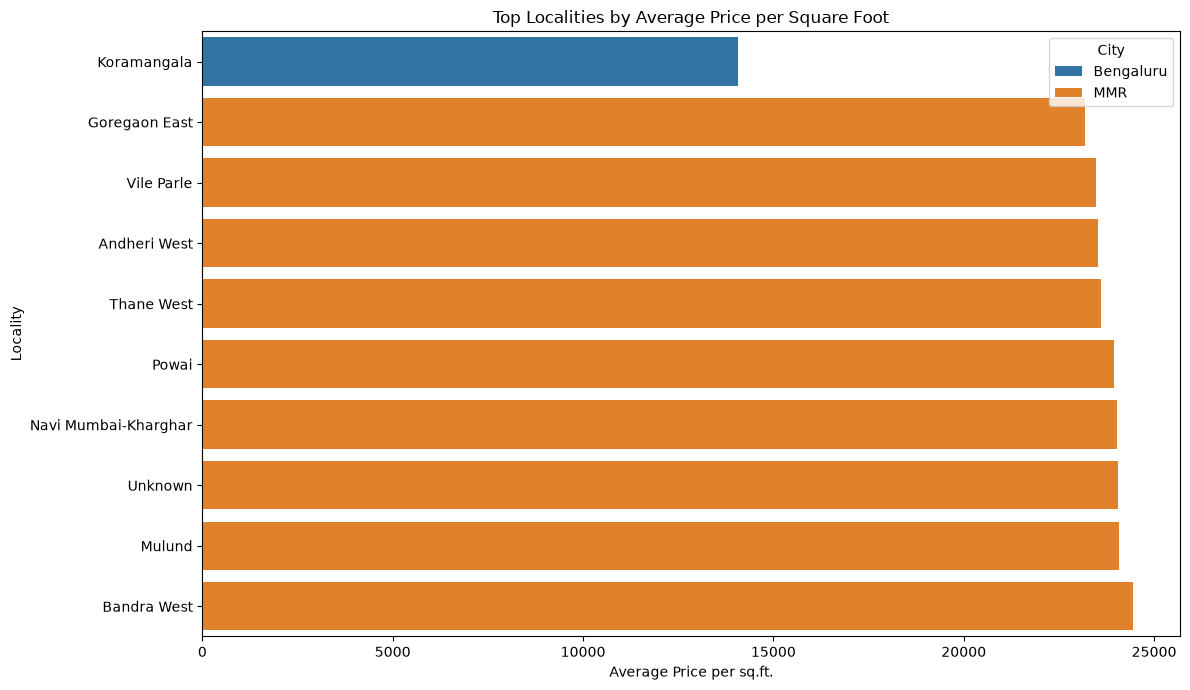

In [100]:
plt.figure(figsize=(12, 7))

plot_data = top_localities_ppsf.sort_values(
    'Average_Price_per_sqft'
)

sns.barplot(
    data=plot_data,
    x='Average_Price_per_sqft',
    y='Locality',
    hue='City',
    dodge=False
)

plt.title('Top Localities by Average Price per Square Foot')
plt.xlabel('Average Price per sq.ft.')
plt.ylabel('Locality')

plt.tight_layout()
plt.show()

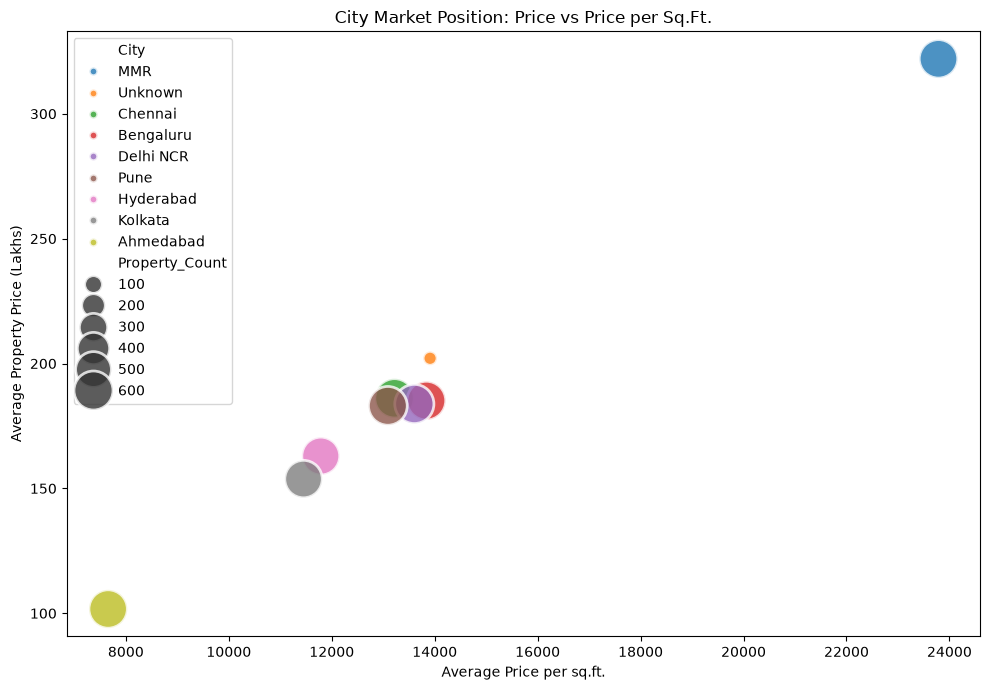

In [101]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=city_market.reset_index(),
    x='Average_Price_per_sqft',
    y='Average_Price_Lakhs',
    size='Property_Count',
    hue='City',
    sizes=(100, 800),
    alpha=0.8
)

plt.title('City Market Position: Price vs Price per Sq.Ft.')
plt.xlabel('Average Price per sq.ft.')
plt.ylabel('Average Property Price (Lakhs)')

plt.tight_layout()
plt.show()

In [102]:
city_market.to_csv(
    'city_market_analysis.csv'
)

locality_market.to_csv(
    'locality_market_analysis.csv',
    index=False
)

locality_reliable.to_csv(
    'reliable_locality_analysis.csv',
    index=False
)

## 14. Statistical Analysis and Market Indicators

Statistical analysis is used to summarize the real estate market and
identify important differences between locations and property segments.

Mean, median, minimum, maximum, standard deviation, and price per square
foot are calculated to provide a more complete view of the market.

These indicators will later be used as key performance indicators (KPIs)
and analytical insights in the Streamlit dashboard.

In [103]:
market_stats = {
    'Total Properties': clean_data['ListingID'].nunique(),
    'Average Price (Lakhs)': clean_data['Price_Lakhs'].mean(),
    'Median Price (Lakhs)': clean_data['Price_Lakhs'].median(),
    'Minimum Price (Lakhs)': clean_data['Price_Lakhs'].min(),
    'Maximum Price (Lakhs)': clean_data['Price_Lakhs'].max(),
    'Average Price/sq.ft.': clean_data['Price_per_sqft'].mean(),
    'Median Price/sq.ft.': clean_data['Price_per_sqft'].median(),
    'Average Carpet Area (sq.ft.)': clean_data['CarpetArea_sqft'].mean(),
    'Median Carpet Area (sq.ft.)': clean_data['CarpetArea_sqft'].median()
}

market_stats = pd.Series(market_stats)

print(market_stats.round(2))

Total Properties                 2364.00
Average Price (Lakhs)             185.34
Median Price (Lakhs)              153.10
Minimum Price (Lakhs)              20.00
Maximum Price (Lakhs)            1342.00
Average Price/sq.ft.            13580.53
Median Price/sq.ft.             12579.00
Average Carpet Area (sq.ft.)     1333.16
Median Carpet Area (sq.ft.)      1208.00
dtype: float64


In [104]:
overall_statistics = pd.DataFrame({
    'Metric': [
        'Price',
        'Price per sq.ft.',
        'Carpet Area'
    ],
    'Mean': [
        clean_data['Price_Lakhs'].mean(),
        clean_data['Price_per_sqft'].mean(),
        clean_data['CarpetArea_sqft'].mean()
    ],
    'Median': [
        clean_data['Price_Lakhs'].median(),
        clean_data['Price_per_sqft'].median(),
        clean_data['CarpetArea_sqft'].median()
    ],
    'Minimum': [
        clean_data['Price_Lakhs'].min(),
        clean_data['Price_per_sqft'].min(),
        clean_data['CarpetArea_sqft'].min()
    ],
    'Maximum': [
        clean_data['Price_Lakhs'].max(),
        clean_data['Price_per_sqft'].max(),
        clean_data['CarpetArea_sqft'].max()
    ],
    'Std_Dev': [
        clean_data['Price_Lakhs'].std(),
        clean_data['Price_per_sqft'].std(),
        clean_data['CarpetArea_sqft'].std()
    ]
})

print(overall_statistics.round(2))

             Metric      Mean   Median  Minimum   Maximum  Std_Dev
0             Price    185.34    153.1    20.00   1342.00   127.66
1  Price per sq.ft.  13580.53  12579.0  5283.02  41251.56  4822.95
2       Carpet Area   1333.16   1208.0   300.00   4185.00   673.57


In [105]:
city_market_display = city_market.copy()

print(city_market_display.round(2))

           Property_Count  Average_Price_Lakhs  Median_Price_Lakhs  \
City                                                                 
MMR                   583               321.99              281.30   
Unknown                50               202.09              183.00   
Chennai               610               186.07              160.50   
Bengaluru             592               185.14              162.50   
Delhi NCR             606               183.81              160.30   
Pune                  592               183.06              161.50   
Hyderabad             564               162.94              141.95   
Kolkata               551               153.74              134.10   
Ahmedabad             580               101.72               89.80   

           Average_Price_per_sqft  Median_Price_per_sqft  Average_Carpet_Area  \
City                                                                            
MMR                      23787.03               23181.54           

In [106]:
highest_price_city = (
    city_market['Average_Price_Lakhs']
    .idxmax()
)

print(
    "Highest average-price city:",
    highest_price_city
)

Highest average-price city: MMR


In [107]:
lowest_price_city = (
    city_market['Average_Price_Lakhs']
    .idxmin()
)

print(
    "Lowest average-price city:",
    lowest_price_city
)

Lowest average-price city: Ahmedabad


In [108]:
highest_ppsf_city = (
    city_market['Average_Price_per_sqft']
    .idxmax()
)

print(
    "Highest average price/sq.ft. city:",
    highest_ppsf_city
)

Highest average price/sq.ft. city: MMR


In [109]:
lowest_ppsf_city = (
    city_market['Average_Price_per_sqft']
    .idxmin()
)

print(
    "Lowest average price/sq.ft. city:",
    lowest_ppsf_city
)

Lowest average price/sq.ft. city: Ahmedabad


In [110]:
most_common_bhk = clean_data['BHK'].mode()[0]

print(
    "Most common BHK:",
    most_common_bhk
)

Most common BHK: 3


In [111]:
most_common_property_type = (
    clean_data['PropertyType'].mode()[0]
)

print(
    "Most common property type:",
    most_common_property_type
)

Most common property type: Apartment


In [112]:
most_common_furnishing = (
    clean_data['Furnishing'].mode()[0]
)

print(
    "Most common furnishing:",
    most_common_furnishing
)

Most common furnishing: Unfurnished


In [113]:
city_price_variability = (
    clean_data.groupby('City')
    .agg(
        Average_Price=('Price_Lakhs', 'mean'),
        Median_Price=('Price_Lakhs', 'median'),
        Price_Std_Dev=('Price_Lakhs', 'std'),
        Property_Count=('ListingID', 'count')
    )
    .sort_values(
        'Price_Std_Dev',
        ascending=False
    )
)

print(city_price_variability.round(2))

           Average_Price  Median_Price  Price_Std_Dev  Property_Count
City                                                                 
MMR               321.99        281.30         192.39             583
Unknown           202.09        183.00         119.17              50
Chennai           186.07        160.50         112.36             610
Bengaluru         185.14        162.50         109.71             592
Pune              183.06        161.50         105.83             592
Delhi NCR         183.81        160.30         102.57             606
Hyderabad         162.94        141.95          93.43             564
Kolkata           153.74        134.10          87.61             551
Ahmedabad         101.72         89.80          59.94             580


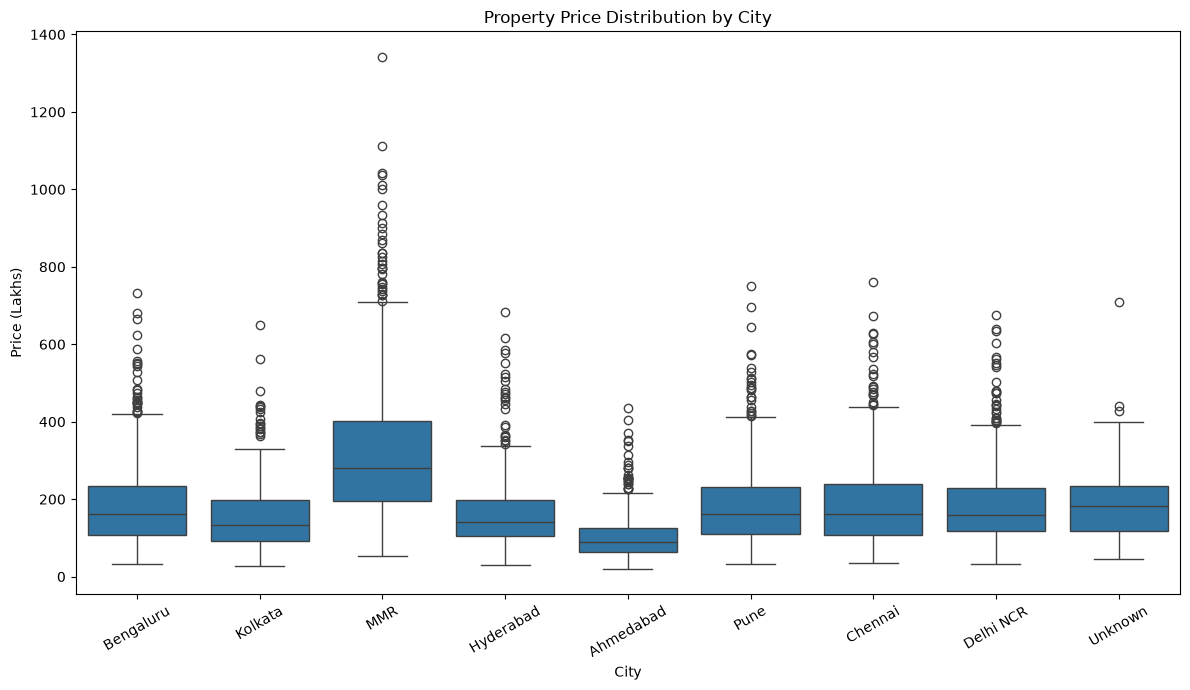

In [114]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=clean_data,
    x='City',
    y='Price_Lakhs'
)

plt.title('Property Price Distribution by City')
plt.xlabel('City')
plt.ylabel('Price (Lakhs)')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [115]:
important_correlations = (
    clean_data[
        [
            'Price_INR',
            'BHK',
            'Bathrooms',
            'CarpetArea_sqft',
            'BuiltUpArea_sqft',
            'SuperBuiltUpArea_sqft',
            'AgeYears',
            'AmenitiesCount',
            'Price_per_sqft'
        ]
    ]
    .corr()['Price_INR']
    .drop('Price_INR')
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(important_correlations.round(3))

SuperBuiltUpArea_sqft    0.821
BuiltUpArea_sqft         0.815
CarpetArea_sqft          0.809
BHK                      0.716
Bathrooms                0.673
Price_per_sqft           0.628
AgeYears                -0.076
AmenitiesCount          -0.020
Name: Price_INR, dtype: float64


In [116]:
insights = {
    'total_properties': clean_data['ListingID'].nunique(),
    'average_price_lakhs': clean_data['Price_Lakhs'].mean(),
    'median_price_lakhs': clean_data['Price_Lakhs'].median(),
    'average_ppsf': clean_data['Price_per_sqft'].mean(),
    'highest_price_city': highest_price_city,
    'lowest_price_city': lowest_price_city,
    'highest_ppsf_city': highest_ppsf_city,
    'most_common_bhk': most_common_bhk,
    'most_common_property_type': most_common_property_type
}

print(insights)

{'total_properties': 2364, 'average_price_lakhs': np.float64(185.3415397631134), 'median_price_lakhs': np.float64(153.1), 'average_ppsf': np.float64(13580.53251781494), 'highest_price_city': 'MMR', 'lowest_price_city': 'Ahmedabad', 'highest_ppsf_city': 'MMR', 'most_common_bhk': np.int64(3), 'most_common_property_type': 'Apartment'}


In [117]:
overall_statistics.to_csv(
    'overall_market_statistics.csv',
    index=False
)

city_price_variability.to_csv(
    'city_price_variability.csv'
)

## 15. Market Insights

The statistical and exploratory analysis is converted into
data-driven market insights.

The insights summarize the overall market, city-level differences,
property segments, price per square foot, and property characteristics.

All conclusions are generated from the analyzed dataset rather than
being manually hard-coded.

In [118]:
total_properties = clean_data['ListingID'].nunique()

average_price = clean_data['Price_Lakhs'].mean()
median_price = clean_data['Price_Lakhs'].median()

average_ppsf = clean_data['Price_per_sqft'].mean()
median_ppsf = clean_data['Price_per_sqft'].median()

average_area = clean_data['CarpetArea_sqft'].mean()
median_area = clean_data['CarpetArea_sqft'].median()

print("===== OVERALL MARKET INSIGHTS =====")

print(f"Total properties analyzed: {total_properties:,}")

print(
    f"Average property price: "
    f"₹{average_price:.2f} Lakhs"
)

print(
    f"Median property price: "
    f"₹{median_price:.2f} Lakhs"
)

print(
    f"Average price per sq.ft.: "
    f"₹{average_ppsf:,.2f}"
)

print(
    f"Median price per sq.ft.: "
    f"₹{median_ppsf:,.2f}"
)

print(
    f"Average carpet area: "
    f"{average_area:.2f} sq.ft."
)

print(
    f"Median carpet area: "
    f"{median_area:.2f} sq.ft."
)

===== OVERALL MARKET INSIGHTS =====
Total properties analyzed: 2,364
Average property price: ₹185.34 Lakhs
Median property price: ₹153.10 Lakhs
Average price per sq.ft.: ₹13,580.53
Median price per sq.ft.: ₹12,579.00
Average carpet area: 1333.16 sq.ft.
Median carpet area: 1208.00 sq.ft.


In [119]:
highest_price_city = city_market[
    'Average_Price_Lakhs'
].idxmax()

lowest_price_city = city_market[
    'Average_Price_Lakhs'
].idxmin()

highest_ppsf_city = city_market[
    'Average_Price_per_sqft'
].idxmax()

lowest_ppsf_city = city_market[
    'Average_Price_per_sqft'
].idxmin()

largest_supply_city = city_market[
    'Property_Count'
].idxmax()

print("===== CITY MARKET INSIGHTS =====")

print(
    f"Highest average property price: "
    f"{highest_price_city}"
)

print(
    f"Lowest average property price: "
    f"{lowest_price_city}"
)

print(
    f"Highest average price per sq.ft.: "
    f"{highest_ppsf_city}"
)

print(
    f"Lowest average price per sq.ft.: "
    f"{lowest_ppsf_city}"
)

print(
    f"Largest number of listings in the dataset: "
    f"{largest_supply_city}"
)

===== CITY MARKET INSIGHTS =====
Highest average property price: MMR
Lowest average property price: Ahmedabad
Highest average price per sq.ft.: MMR
Lowest average price per sq.ft.: Ahmedabad
Largest number of listings in the dataset: Chennai


In [120]:
most_common_bhk = clean_data['BHK'].mode()[0]

most_common_property_type = (
    clean_data['PropertyType'].mode()[0]
)

most_common_furnishing = (
    clean_data['Furnishing'].mode()[0]
)

print("===== PROPERTY SEGMENT INSIGHTS =====")

print(
    f"Most common BHK configuration: "
    f"{most_common_bhk} BHK"
)

print(
    f"Most common property type: "
    f"{most_common_property_type}"
)

print(
    f"Most common furnishing status: "
    f"{most_common_furnishing}"
)

===== PROPERTY SEGMENT INSIGHTS =====
Most common BHK configuration: 3 BHK
Most common property type: Apartment
Most common furnishing status: Unfurnished


In [121]:
top_locality = locality_reliable.iloc[
    locality_reliable[
        'Average_Price_per_sqft'
    ].argmax()
]

print("===== TOP LOCALITY =====")

print(
    f"Locality: {top_locality['Locality']}"
)

print(
    f"City: {top_locality['City']}"
)

print(
    f"Average price per sq.ft.: "
    f"₹{top_locality['Average_Price_per_sqft']:,.2f}"
)

print(
    f"Listings analyzed: "
    f"{int(top_locality['Property_Count'])}"
)

===== TOP LOCALITY =====
Locality: Bandra West
City: MMR
Average price per sq.ft.: ₹24,457.47
Listings analyzed: 72


In [122]:
market_insights = pd.DataFrame({
    'Insight': [
        'Total Properties',
        'Average Property Price',
        'Median Property Price',
        'Average Price per Sq.Ft.',
        'Median Price per Sq.Ft.',
        'Average Carpet Area',
        'Most Common BHK',
        'Most Common Property Type',
        'Highest Average Price City',
        'Lowest Average Price City',
        'Highest Price per Sq.Ft. City',
        'Largest Listing Supply City'
    ],
    
    'Value': [
        total_properties,
        round(average_price, 2),
        round(median_price, 2),
        round(average_ppsf, 2),
        round(median_ppsf, 2),
        round(average_area, 2),
        most_common_bhk,
        most_common_property_type,
        highest_price_city,
        lowest_price_city,
        highest_ppsf_city,
        largest_supply_city
    ]
})

print(market_insights)

                          Insight      Value
0                Total Properties       2364
1          Average Property Price     185.34
2           Median Property Price      153.1
3        Average Price per Sq.Ft.   13580.53
4         Median Price per Sq.Ft.    12579.0
5             Average Carpet Area    1333.16
6                 Most Common BHK          3
7       Most Common Property Type  Apartment
8      Highest Average Price City        MMR
9       Lowest Average Price City  Ahmedabad
10  Highest Price per Sq.Ft. City        MMR
11    Largest Listing Supply City    Chennai


In [123]:
market_insights.to_csv(
    'market_insights.csv',
    index=False
)

In [124]:
dashboard_metrics = {
    'total_properties': int(total_properties),
    'average_price': round(average_price, 2),
    'median_price': round(median_price, 2),
    'average_ppsf': round(average_ppsf, 2),
    'median_ppsf': round(median_ppsf, 2),
    'average_area': round(average_area, 2),
    'most_common_bhk': int(most_common_bhk),
    'most_common_property_type': most_common_property_type,
    'highest_price_city': highest_price_city,
    'lowest_price_city': lowest_price_city,
    'highest_ppsf_city': highest_ppsf_city,
    'largest_supply_city': largest_supply_city
}

print(dashboard_metrics)

{'total_properties': 2364, 'average_price': np.float64(185.34), 'median_price': np.float64(153.1), 'average_ppsf': np.float64(13580.53), 'median_ppsf': np.float64(12579.0), 'average_area': np.float64(1333.16), 'most_common_bhk': 3, 'most_common_property_type': 'Apartment', 'highest_price_city': 'MMR', 'lowest_price_city': 'Ahmedabad', 'highest_ppsf_city': 'MMR', 'largest_supply_city': 'Chennai'}


## 16. Machine Learning — Property Price Prediction

A machine-learning model is developed to estimate property prices
based on property characteristics.

The target variable is Price_INR.

Features include property size, BHK, bathrooms, location, property
type, furnishing, building characteristics, amenities, and other
available property attributes.

The target price itself is excluded from the input features to prevent
data leakage.

### 16.1 Target Variable and Feature Selection

The target variable for the machine-learning model is `Price_INR`.

Property characteristics such as location, property type, BHK,
property size, bathrooms, furnishing, building characteristics,
amenities, and geographical information are used as input features.

The target variable is excluded from the feature set to prevent
data leakage.

In [125]:
# Target variable
target = 'Price_INR'

# Input features
features = [
    'City',
    'Locality',
    'PropertyType',
    'BHK',
    'Bathrooms',
    'Balconies',
    'Furnishing',
    'SuperBuiltUpArea_sqft',
    'BuiltUpArea_sqft',
    'CarpetArea_sqft',
    'Floor',
    'TotalFloors',
    'Parking',
    'BuildingType',
    'YearBuilt',
    'AgeYears',
    'Facing',
    'AmenitiesCount',
    'IsRERARegistered',
    'Latitude',
    'Longitude'
]

print("Target variable:", target)
print("\nNumber of features:", len(features))
print("\nFeatures:")
print(features)

Target variable: Price_INR

Number of features: 21

Features:
['City', 'Locality', 'PropertyType', 'BHK', 'Bathrooms', 'Balconies', 'Furnishing', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'Parking', 'BuildingType', 'YearBuilt', 'AgeYears', 'Facing', 'AmenitiesCount', 'IsRERARegistered', 'Latitude', 'Longitude']


### 16.2 Training and Test Data Preparation

The combined training dataset is used to train the machine-learning
models.

The separate test dataset is kept completely unseen during model
training. Since the test dataset does not contain the actual
`Price_INR` values, it will later be used for generating final
property-price predictions.

In [126]:
# Training data
X_train = train_data[features].copy()
y_train = train_data[target].copy()

# Separate test data
X_test = test_data[features].copy()

print("Training features shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Test features shape:", X_test.shape)


Training features shape: (4728, 21)
Training target shape: (4728,)
Test features shape: (4728, 21)


In [127]:
print("\nTarget column:", y_train.name)

print("\nTraining features:")
print(X_train.columns.tolist())

print("\nTest features:")
print(X_test.columns.tolist())


Target column: Price_INR

Training features:
['City', 'Locality', 'PropertyType', 'BHK', 'Bathrooms', 'Balconies', 'Furnishing', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'Parking', 'BuildingType', 'YearBuilt', 'AgeYears', 'Facing', 'AmenitiesCount', 'IsRERARegistered', 'Latitude', 'Longitude']

Test features:
['City', 'Locality', 'PropertyType', 'BHK', 'Bathrooms', 'Balconies', 'Furnishing', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'Parking', 'BuildingType', 'YearBuilt', 'AgeYears', 'Facing', 'AmenitiesCount', 'IsRERARegistered', 'Latitude', 'Longitude']


### 16.4 Numerical and Categorical Feature Identification

Numerical and categorical variables require different preprocessing
techniques.

Numerical variables will be handled using median imputation, while
categorical variables will be imputed using their most frequent value
and converted into numerical form using one-hot encoding.

In [128]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'string', 'bool']
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['BHK', 'Bathrooms', 'Balconies', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'YearBuilt', 'AgeYears', 'AmenitiesCount', 'Latitude', 'Longitude']

Categorical features:
['City', 'Locality', 'PropertyType', 'Furnishing', 'Parking', 'BuildingType', 'Facing', 'IsRERARegistered']


In [129]:
print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Number of numerical features: 13
Number of categorical features: 8


### 16.5 Numerical Feature Preprocessing

Missing numerical values are replaced with the median value of the
corresponding feature.

Median imputation is used because it is less sensitive to extreme
values and outliers than mean imputation.

In [130]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

print("Numerical preprocessing created.")
print("Categorical preprocessing created.")

Numerical preprocessing created.
Categorical preprocessing created.


### 16.6 Categorical Feature Preprocessing

Missing categorical values are replaced using the most frequent value.

Categorical variables are then converted into numerical variables using
one-hot encoding.

`handle_unknown='ignore'` ensures that previously unseen categories in
the separate test dataset do not cause an error during prediction.

In [131]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

print("Categorical preprocessing pipeline created successfully.")

Categorical preprocessing pipeline created successfully.


### 16.7 Combined Preprocessing Pipeline

A ColumnTransformer is used to apply the appropriate preprocessing
method to numerical and categorical variables.

This ensures that the same preprocessing logic is consistently applied
during model training and later during prediction on the test dataset.

In [132]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            numeric_transformer,
            numeric_features
        ),
        (
            'cat',
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Combined preprocessing pipeline created successfully.")


Combined preprocessing pipeline created successfully.


### 16.8 Machine Learning Data Preparation Verification

The final verification checks the training and test feature dimensions,
the target variable, selected features, and the preprocessing pipeline
before model training begins.

In [133]:
print("=" * 60)
print("MACHINE LEARNING DATA PREPARATION - FINAL CHECK")
print("=" * 60)

print("\nTarget variable:")
print(target)

print("\nNumber of input features:")
print(len(features))

print("\nTraining feature shape:")
print(X_train.shape)

print("\nTraining target shape:")
print(y_train.shape)

print("\nTest feature shape:")
print(X_test.shape)

print("\nNumber of numerical features:")
print(len(numeric_features))

print("\nNumber of categorical features:")
print(len(categorical_features))

print("\nTarget excluded from features:")
print(target not in features)

print("\nPreprocessor:")
print(preprocessor)

MACHINE LEARNING DATA PREPARATION - FINAL CHECK

Target variable:
Price_INR

Number of input features:
21

Training feature shape:
(4728, 21)

Training target shape:
(4728,)

Test feature shape:
(4728, 21)

Number of numerical features:
13

Number of categorical features:
8

Target excluded from features:
True

Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['BHK', 'Bathrooms', 'Balconies',
                                  'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft',
                                  'CarpetArea_sqft', 'Floor', 'TotalFloors',
                                  'YearBuilt', 'AgeYears', 'AmenitiesCount',
                                  'Latitude', 'Longitude']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                       

### 17. Model Training — Baseline Model

Before comparing advanced models, we first train a baseline Linear Regression model.

This gives us a reference performance that we can later compare with stronger models such as Random Forest and Gradient Boosting.

### 17.1 Baseline Linear Regression Model

Linear Regression is used as the baseline machine-learning model for
property price prediction.

The preprocessing pipeline is included within the model pipeline so that
missing values and categorical variables are handled consistently
during training and prediction.

In [134]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression pipeline
linear_regression_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

print("Linear Regression pipeline created successfully.")

Linear Regression pipeline created successfully.


### 17.2 Train the Baseline Model

The Linear Regression model is trained using the complete training
dataset.

The target variable is `Price_INR`, while the selected property
characteristics are used as input features.

In [135]:
# Train the baseline model
linear_regression_model.fit(
    X_train,
    y_train
)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [136]:
# Generate predictions on training data
y_train_pred_linear = linear_regression_model.predict(
    X_train
)

print("Number of training predictions:", len(y_train_pred_linear))
print("\nFirst 10 predictions:")
print(y_train_pred_linear[:10])

Number of training predictions: 4728

First 10 predictions:
[17102877.10291708  6214525.18184543  3351243.29457104 24598812.22943574
 21100668.58714437  6893549.30914694 16622849.03242451  2517422.6298064
 10422305.95618182 16865178.94764501]


In [137]:
comparison = pd.DataFrame({
    'Actual_Price_INR': y_train.values,
    'Predicted_Price_INR': y_train_pred_linear
})

print(comparison.head(10))

   Actual_Price_INR  Predicted_Price_INR
0          17770000         1.710288e+07
1           7130000         6.214525e+06
2           5920000         3.351243e+06
3          19140000         2.459881e+07
4          20300000         2.110067e+07
5           9230000         6.893549e+06
6          14890000         1.662285e+07
7           5020000         2.517423e+06
8          10070000         1.042231e+07
9          16660000         1.686518e+07


In [138]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_linear = mean_absolute_error(
    y_train,
    y_train_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_linear
    )
)

r2_linear = r2_score(
    y_train,
    y_train_pred_linear
)

print("Linear Regression - Training Performance")
print("------------------------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression - Training Performance
------------------------------------------
MAE : 2339541.5512091983
RMSE: 3845300.707381914
R²  : 0.9092512105721227


## 18. Cross-Validation and Model Evaluation

Five-fold cross-validation is used to evaluate the machine-learning
model more reliably.

The training dataset is divided into five folds. The model is trained
on four folds and validated on the remaining fold, and this process is
repeated five times.

MAE, RMSE, and R² are calculated across the folds to measure model
performance.

In [139]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_validate(
    linear_regression_model,
    X_train,
    y_train,
    cv=kf,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    n_jobs=-1
)

print("5-Fold Cross-Validation Results")
print("--------------------------------")

print("Mean MAE:",
      -cv_scores['test_MAE'].mean())

print("Mean RMSE:",
      -cv_scores['test_RMSE'].mean())

print("Mean R²:",
      cv_scores['test_R2'].mean())

5-Fold Cross-Validation Results
--------------------------------
Mean MAE: 2405709.180381982
Mean RMSE: 3957241.70613496
Mean R²: 0.9035119911739586


### 18.1 Random Forest Regression

Random Forest Regression is trained as a second model for property price
prediction.

It can capture non-linear relationships between property characteristics
such as area, BHK, location, amenities, and property age that may not be
captured effectively by Linear Regression.

In [140]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


### 18.2 Train Random Forest Regression Model

The Random Forest Regression model is trained using the complete
training dataset.

The preprocessing pipeline automatically handles missing values and
categorical variables before the data is passed to the Random Forest
algorithm.

In [141]:
random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 18.3 Random Forest Cross-Validation

The Random Forest model is evaluated using 5-fold cross-validation.

The same MAE, RMSE, and R² metrics used for Linear Regression are used
so that both models can be compared fairly.

In [153]:
random_forest_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=kf,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    n_jobs=-1
)

random_forest_mae = -random_forest_cv['test_MAE'].mean()
random_forest_rmse = -random_forest_cv['test_RMSE'].mean()
random_forest_r2 = random_forest_cv['test_R2'].mean()

print("Random Forest - 5-Fold Cross-Validation")
print("----------------------------------------")
print("Mean MAE :", random_forest_mae)
print("Mean RMSE:", random_forest_rmse)
print("Mean R²  :", random_forest_r2)

Random Forest - 5-Fold Cross-Validation
----------------------------------------
Mean MAE : 1541996.3786331385
Mean RMSE: 2573830.0335961366
Mean R²  : 0.9588866442190435


### 18.4 Gradient Boosting Regression

Gradient Boosting Regression is used as a third machine-learning
model for property price prediction.

The model can capture complex and non-linear relationships between
property characteristics and property prices.

In [143]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            GradientBoostingRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


### 18.5 Train Gradient Boosting Regression Model

The Gradient Boosting Regression model is trained using the complete
training dataset.

The preprocessing pipeline handles missing values and categorical
variables before the data is passed to the Gradient Boosting algorithm.

In [144]:
gradient_boosting_model.fit(
    X_train,
    y_train
)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


### 18.6 Gradient Boosting Cross-Validation

The Gradient Boosting model is evaluated using 5-fold cross-validation.

MAE, RMSE, and R² are calculated to measure prediction performance and
to allow a fair comparison with Linear Regression and Random Forest.

In [145]:
gradient_boosting_cv = cross_validate(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=kf,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    n_jobs=-1
)

gradient_boosting_mae = -gradient_boosting_cv['test_MAE'].mean()
gradient_boosting_rmse = -gradient_boosting_cv['test_RMSE'].mean()
gradient_boosting_r2 = gradient_boosting_cv['test_R2'].mean()

print("Gradient Boosting - 5-Fold Cross-Validation")
print("---------------------------------------------")
print("Mean MAE :", gradient_boosting_mae)
print("Mean RMSE:", gradient_boosting_rmse)
print("Mean R²  :", gradient_boosting_r2)

Gradient Boosting - 5-Fold Cross-Validation
---------------------------------------------
Mean MAE : 1354881.8982330568
Mean RMSE: 2124395.4231456104
Mean R²  : 0.9720256933104231


### 18.7 Model Performance Comparison

The three regression models are compared using their 5-fold
cross-validation performance.

MAE and RMSE are error metrics, where lower values indicate better
performance. R² measures the proportion of price variation explained
by the model, where higher values indicate better performance.

In [146]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        -cv_scores['test_MAE'].mean(),
        random_forest_mae,
        gradient_boosting_mae
    ],
    'RMSE': [
        -cv_scores['test_RMSE'].mean(),
        random_forest_rmse,
        gradient_boosting_rmse
    ],
    'R2': [
        cv_scores['test_R2'].mean(),
        random_forest_r2,
        gradient_boosting_r2
    ]
})

model_comparison = model_comparison.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

print(model_comparison.round(2))

               Model         MAE        RMSE    R2
0  Gradient Boosting  1354881.90  2124395.42  0.97
1      Random Forest  1541996.38  2573830.03  0.96
2  Linear Regression  2405709.18  3957241.71  0.90


### 18.8 Best Model Selection

The model with the lowest cross-validation RMSE is selected as the
best-performing model.

RMSE is used as the primary selection metric because it gives greater
penalty to larger prediction errors, which is important for property
price prediction.

In [147]:
# Select the model with the lowest cross-validation RMSE
best_model_name = model_comparison.loc[
    model_comparison['RMSE'].idxmin(),
    'Model'
]

print("Best Model:", best_model_name)

Best Model: Gradient Boosting


In [46]:
model_dict = {
    'Linear Regression': linear_regression_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_boosting_model
}

best_model = model_dict[best_model_name]

print("\nSelected model pipeline:")
print(best_model)


Selected model pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['BHK', 'Bathrooms',
                                                   'Balconies',
                                                   'SuperBuiltUpArea_sqft',
                                                   'BuiltUpArea_sqft',
                                                   'CarpetArea_sqft', 'Floor',
                                                   'TotalFloors', 'YearBuilt',
                                                   'AgeYears', 'AmenitiesCount',
                                                   'Latitude', 'Longitude']),
                                                 ('cat',
                                              

### 18.9 Final Training of the Selected Model

The best-performing model identified through 5-fold cross-validation is
now trained on the complete training dataset.

This allows the selected model to learn from all available training
observations before it is used to generate predictions for the separate
test dataset.

In [47]:
# Train the selected model on the complete training dataset
best_model.fit(
    X_train,
    y_train
)

print("Selected model trained successfully.")
print("Model:", best_model_name)

Selected model trained successfully.
Model: Gradient Boosting


## 19. Final Property Price Prediction

The selected machine-learning model is used to predict property prices
for the separate test dataset.

The test dataset does not contain the actual `Price_INR` values, so it
is used only for generating final predictions and not for calculating
MAE, RMSE, or R².

In [48]:
# Generate price predictions for the separate test dataset
test_predictions = best_model.predict(X_test)

print("Number of predictions:", len(test_predictions))
print("\nFirst 10 predicted prices:")
print(test_predictions[:10])

Number of predictions: 4728

First 10 predicted prices:
[13341573.38138559 12973629.25381048  4391442.81604315 34747556.29429508
  9583433.17631106 15500007.59929348 10600724.6940363   3502981.94333495
 16112380.78721628 42218946.34165075]


### 19.1 Add Predicted Prices to Test Data

The predicted property prices are added to the test dataset as a new
column named `Predicted_Price_INR`.

This allows each property listing to be associated with its predicted
market price.

In [49]:
# Create a copy of the test dataset
test_predictions_data = test_data.copy()

# Add predicted prices
test_predictions_data['Predicted_Price_INR'] = test_predictions

print("Predictions added successfully.")

print("\nShape of prediction dataset:")
print(test_predictions_data.shape)

Predictions added successfully.

Shape of prediction dataset:
(4728, 24)


In [50]:
print(
    test_predictions_data[
        [
            'ListingID',
            'City',
            'Locality',
            'PropertyType',
            'BHK',
            'SuperBuiltUpArea_sqft',
            'Predicted_Price_INR'
        ]
    ].head(10)
)

  ListingID       City     Locality       PropertyType  BHK  \
0  HP501139    Kolkata   Tollygunge          Row House    2   
1  HP501630       Pune    Hinjawadi          Apartment    2   
2  HP501608  Ahmedabad     Bodakdev          Apartment    1   
3  HP501979    Chennai      T Nagar  Independent House    5   
4  HP501399  Ahmedabad    Maninagar          Apartment    3   
5  HP500219        NaN  Bandra West          Apartment    2   
6  HP502088    Kolkata   Tollygunge          Apartment    3   
7  HP500253    Kolkata    Salt Lake             Studio    0   
8  HP501279  Bengaluru   HSR Layout  Independent House    2   
9  HP500644        MMR        Powai          Apartment    3   

   SuperBuiltUpArea_sqft  Predicted_Price_INR  
0                   1775         1.334157e+07  
1                   1434         1.297363e+07  
2                    883         4.391443e+06  
3                   3840         3.474756e+07  
4                   1922         9.583433e+06  
5                 

### 19.2 Prediction Validation

The predicted prices are checked for missing values and invalid values
before the prediction dataset is saved.

Every test property should have exactly one predicted price.

In [51]:
# Check for missing predictions
missing_predictions = test_predictions_data[
    'Predicted_Price_INR'
].isna().sum()

# Check for infinite predictions
infinite_predictions = np.isinf(
    test_predictions_data['Predicted_Price_INR']
).sum()

# Check prediction count
prediction_count = len(
    test_predictions_data['Predicted_Price_INR']
)

test_row_count = len(test_data)

print("Total test records:", test_row_count)
print("Total predictions:", prediction_count)
print("Missing predictions:", missing_predictions)
print("Infinite predictions:", infinite_predictions)

Total test records: 4728
Total predictions: 4728
Missing predictions: 0
Infinite predictions: 0


### 19.3 Save Test Predictions

The test dataset containing the model's predicted property prices is
saved as a CSV file.

This file can later be used for analysis and visualization in the
Real Estate Market Analysis Dashboard.

In [52]:
# Save test data with predicted prices
prediction_file = 'real_estate_test_predictions.csv'

test_predictions_data.to_csv(
    prediction_file,
    index=False
)

print("Prediction file saved successfully:")
print(prediction_file)

Prediction file saved successfully:
real_estate_test_predictions.csv


In [53]:
import os

if os.path.exists(prediction_file):
    print("\n✓ File exists.")
    print("File size:", os.path.getsize(prediction_file), "bytes")
else:
    print("\n✗ File was not saved.")


✓ File exists.
File size: 833210 bytes


## 20. Feature Importance and Model Interpretation

The selected machine-learning model is analyzed to identify the
features that contribute most strongly to property price prediction.

Feature importance helps explain which property characteristics,
locations, sizes, amenities, and other attributes are most influential
in the model's predictions.

In [54]:
# Access the trained model inside the pipeline
model = best_model.named_steps['model']

# Check whether the selected model provides feature importance
if hasattr(model, 'feature_importances_'):
    print("The selected model provides feature importance.")

elif hasattr(model, 'coef_'):
    print("The selected model provides coefficients.")

else:
    print(
        "The selected model does not provide direct feature importance."
    )

The selected model provides feature importance.


### 20.1 Extract Feature Importance

The fitted preprocessing pipeline is used to obtain the names of all
transformed features.

For tree-based models, feature importance values are then matched with
these transformed feature names.

In [55]:
# Get the fitted preprocessor from the selected model
fitted_preprocessor = best_model.named_steps['preprocessor']

# Get transformed feature names
transformed_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

print("Number of transformed features:",
      len(transformed_feature_names))

print("\nFirst 20 transformed features:")
print(transformed_feature_names[:20])

Number of transformed features: 109

First 20 transformed features:
['num__BHK' 'num__Bathrooms' 'num__Balconies' 'num__SuperBuiltUpArea_sqft'
 'num__BuiltUpArea_sqft' 'num__CarpetArea_sqft' 'num__Floor'
 'num__TotalFloors' 'num__YearBuilt' 'num__AgeYears' 'num__AmenitiesCount'
 'num__Latitude' 'num__Longitude' 'cat__City_Ahmedabad'
 'cat__City_Bengaluru' 'cat__City_Chennai' 'cat__City_Delhi NCR'
 'cat__City_Hyderabad' 'cat__City_Kolkata' 'cat__City_MMR']


In [56]:
if hasattr(model, 'feature_importances_'):

    feature_importance_values = model.feature_importances_

    feature_importance_df = pd.DataFrame({
        'Feature': transformed_feature_names,
        'Importance': feature_importance_values
    })

    feature_importance_df = feature_importance_df.sort_values(
        by='Importance',
        ascending=False
    ).reset_index(drop=True)

    print("\nTop 20 Important Features:")
    print(feature_importance_df.head(20))

else:
    print(
        "Feature importance is not directly available "
        "for the selected model."
    )


Top 20 Important Features:
                                Feature  Importance
0            num__SuperBuiltUpArea_sqft    0.632284
1                         cat__City_MMR    0.211855
2                 num__BuiltUpArea_sqft    0.043738
3           cat__PropertyType_Penthouse    0.032350
4                        num__Longitude    0.027485
5                   cat__City_Ahmedabad    0.019306
6               cat__PropertyType_Villa    0.008190
7                  num__CarpetArea_sqft    0.007921
8                         num__Latitude    0.003335
9                         num__AgeYears    0.002329
10                       num__YearBuilt    0.001802
11          cat__Furnishing_Unfurnished    0.001657
12  cat__PropertyType_Independent House    0.001396
13            cat__Furnishing_Furnished    0.001015
14                  cat__City_Hyderabad    0.000937
15                    cat__City_Kolkata    0.000897
16                       num__Bathrooms    0.000489
17                             num__

### 20.2 Feature Importance Ranking

The transformed features are ranked according to their importance in
the selected machine-learning model.

The top features will be used to understand which property
characteristics have the strongest influence on predicted property
prices.

In [57]:
# Create a clean ranking of feature importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Add ranking
feature_importance_df.insert(
    0,
    'Rank',
    range(1, len(feature_importance_df) + 1)
)

print("Top 15 Most Important Features:")
print(
    feature_importance_df[
        ['Rank', 'Feature', 'Importance']
    ].head(15).to_string(index=False)
)

Top 15 Most Important Features:
 Rank                             Feature  Importance
    1          num__SuperBuiltUpArea_sqft    0.632284
    2                       cat__City_MMR    0.211855
    3               num__BuiltUpArea_sqft    0.043738
    4         cat__PropertyType_Penthouse    0.032350
    5                      num__Longitude    0.027485
    6                 cat__City_Ahmedabad    0.019306
    7             cat__PropertyType_Villa    0.008190
    8                num__CarpetArea_sqft    0.007921
    9                       num__Latitude    0.003335
   10                       num__AgeYears    0.002329
   11                      num__YearBuilt    0.001802
   12         cat__Furnishing_Unfurnished    0.001657
   13 cat__PropertyType_Independent House    0.001396
   14           cat__Furnishing_Furnished    0.001015
   15                 cat__City_Hyderabad    0.000937


### 20.3 Feature Importance Visualization

The top 15 features contributing to the selected model are visualized
using a horizontal bar chart.

This visualization makes it easier to understand which property
characteristics have the greatest influence on the model.

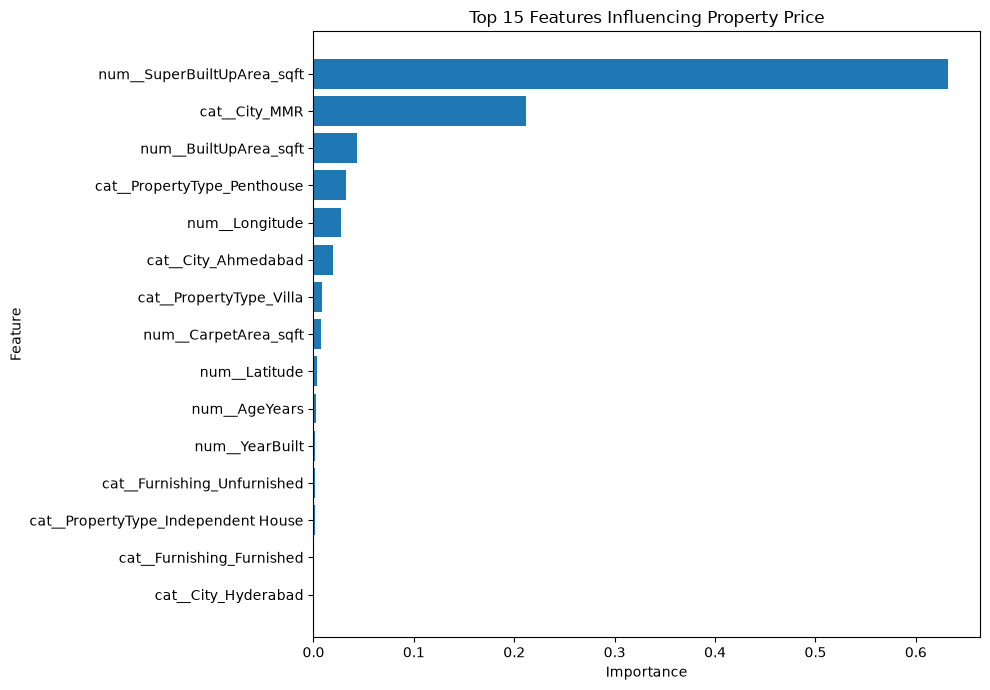

In [58]:
import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 Features Influencing Property Price')

plt.tight_layout()
plt.show()

## 21. Real Estate Market Analysis

The real estate dataset is analyzed to understand overall market
characteristics.

Key metrics such as total property listings, average property price,
median property price, average property size, and average price per
square foot are calculated.

These metrics provide a high-level overview of the real estate market
and will form the foundation of the dashboard.

In [167]:
# Create a separate dataframe for market analysis
market_data = train_data.copy()

# Calculate price per square foot
market_data['Price_per_sqft'] = (
    market_data['Price_INR'] /
    market_data['CarpetArea_sqft']
)

# Remove invalid infinite values, if any
market_data['Price_per_sqft'] = (
    market_data['Price_per_sqft']
    .replace([np.inf, -np.inf], np.nan)
)

# Overall market KPIs
total_listings = len(market_data)

average_price = market_data['Price_INR'].mean()

median_price = market_data['Price_INR'].median()

average_area = market_data['CarpetArea_sqft'].mean()

average_price_per_sqft = (
    market_data['Price_per_sqft'].mean()
)

print("========== REAL ESTATE MARKET OVERVIEW ==========")

print(f"Total Listings          : {total_listings:,}")
print(f"Average Property Price  : ₹{average_price:,.2f}")
print(f"Median Property Price   : ₹{median_price:,.2f}")
print(f"Average Carpet Area     : {average_area:,.2f} sq.ft")
print(
    f"Average Price per Sq.ft : "
    f"₹{average_price_per_sqft:,.2f}"
)

========== REAL ESTATE MARKET OVERVIEW ==========
Total Listings          : 4,728
Average Property Price  : ₹18,534,153.98
Median Property Price   : ₹15,310,000.00
Average Carpet Area     : 1,333.16 sq.ft
Average Price per Sq.ft : ₹13,580.53


## 22. City-Wise Real Estate Market Analysis

The real estate market is analyzed at the city level to compare
property prices, listing volume, and price per square foot across
different cities.

This analysis helps identify relatively expensive and affordable
markets and differences in market activity between cities.

In [168]:
# City-wise market analysis

city_analysis = (
    market_data
    .groupby('City')
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Sort by average property price
city_analysis = city_analysis.sort_values(
    by='Average_Price_INR',
    ascending=False
).reset_index(drop=True)

print("========== CITY-WISE MARKET ANALYSIS ==========")

print(
    city_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== CITY-WISE MARKET ANALYSIS ==========
     City  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
      MMR             583        32199245.28        28130000.0                23787.03
  Unknown              50        20208600.00        18300000.0                13910.22
  Chennai             610        18607180.33        16050000.0                13218.64
Bengaluru             592        18513547.30        16250000.0                13837.25
Delhi NCR             606        18380561.06        16030000.0                13603.92
     Pune             592        18306283.78        16150000.0                13089.62
Hyderabad             564        16293900.71        14195000.0                11786.45
  Kolkata             551        15374264.97        13410000.0                11451.36
Ahmedabad             580        10171672.41         8980000.0                 7655.34


## 23. Property Type Analysis

The dataset is analyzed by property type to compare market availability,
property prices, and price per square foot.

This analysis helps identify differences in pricing and market
distribution among apartments, villas, independent houses, penthouses,
and other property categories.

In [169]:
# Property-type market analysis

property_type_analysis = (
    market_data
    .groupby('PropertyType')
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Sort by average price
property_type_analysis = property_type_analysis.sort_values(
    by='Average_Price_INR',
    ascending=False
).reset_index(drop=True)

print("========== PROPERTY TYPE ANALYSIS ==========")

print(
    property_type_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== PROPERTY TYPE ANALYSIS ==========
     PropertyType  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
        Penthouse             405        34077135.80        30020000.0                17763.49
            Villa             387        29421421.19        26710000.0                15557.72
Independent House             490        24874020.41        21580000.0                12878.45
        Row House             277        16791516.25        14970000.0                14151.83
        Apartment            2777        15702880.81        13920000.0                13009.40
           Studio             392         5091147.96         4785000.0                11826.78


## 24. BHK-Wise Market Analysis

The real estate market is analyzed according to the number of bedrooms
(BHK).

Average price, median price, listing count, and average price per square
foot are calculated for each BHK category.

In [170]:
# BHK-wise market analysis

bhk_analysis = (
    market_data
    .groupby('BHK')
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Sort BHK categories in ascending order
bhk_analysis = bhk_analysis.sort_values(
    by='BHK',
    ascending=True
).reset_index(drop=True)

print("========== BHK-WISE MARKET ANALYSIS ==========")

print(
    bhk_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== BHK-WISE MARKET ANALYSIS ==========
 BHK  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
   0             392         5091147.96         4785000.0                11826.78
   1             434         8156728.11         7620000.0                13153.73
   2            1386        13320310.25        12305000.0                13284.55
   3            1508        20018448.28        18755000.0                13800.64
   4             762        28931561.68        26990000.0                14267.28
   5             189        46008465.61        42780000.0                15242.54
   6              57        47412456.14        43310000.0                15573.31


## 25. Locality-Wise Market Analysis

The real estate market is analyzed at the locality level to identify
areas with higher or lower property prices.

Listing count, average price, median price, and average price per square
foot are calculated for each locality.

In [171]:
# Locality-wise market analysis

locality_analysis = (
    market_data
    .groupby('Locality', dropna=False)
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Remove rows where locality is missing
locality_analysis = locality_analysis[
    locality_analysis['Locality'].notna()
].copy()

# Sort by average price
locality_analysis = locality_analysis.sort_values(
    by='Average_Price_INR',
    ascending=False
).reset_index(drop=True)

print("========== TOP 20 LOCALITIES BY AVERAGE PRICE ==========")

print(
    locality_analysis[
        [
            'Locality',
            'Total_Listings',
            'Average_Price_INR',
            'Median_Price_INR',
            'Average_Price_per_sqft'
        ]
    ]
    .head(20)
    .round(2)
    .to_string(index=False)
)

========== TOP 20 LOCALITIES BY AVERAGE PRICE ==========
            Locality  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
         Bandra West              73        35319178.08        31340000.0                24439.82
          Vile Parle              73        34109589.04        28980000.0                23450.98
               Powai              77        33742337.66        31510000.0                23947.20
Navi Mumbai-Kharghar              66        32333181.82        29140000.0                24033.29
        Andheri West              75        31369200.00        28400000.0                23496.87
              Mulund              68        30952205.88        29875000.0                24117.42
          Thane West              68        30156470.59        25075000.0                23611.16
       Goregaon East              78        28587820.51        24695000.0                23167.13
          HSR Layout              51        20851960.78      

## 26. Price Distribution Analysis

The distribution of property prices is analyzed to understand the
overall price range and variation in the real estate market.

The analysis includes minimum price, maximum price, average price,
median price, and selected percentiles.

In [172]:
# Price distribution statistics

price_distribution = market_data['Price_INR'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

print("========== PROPERTY PRICE DISTRIBUTION ==========")

print(price_distribution)

========== PROPERTY PRICE DISTRIBUTION ==========
count    4.728000e+03
mean     1.853415e+07
std      1.276603e+07
min      2.000000e+06
25%      1.007000e+07
50%      1.531000e+07
75%      2.333000e+07
90%      3.369300e+07
95%      4.265000e+07
max      1.342000e+08
Name: Price_INR, dtype: float64


In [173]:
minimum_price = market_data['Price_INR'].min()
maximum_price = market_data['Price_INR'].max()

price_range = maximum_price - minimum_price

print("\nMinimum Price : ₹{:,.2f}".format(minimum_price))
print("Maximum Price : ₹{:,.2f}".format(maximum_price))
print("Price Range   : ₹{:,.2f}".format(price_range))


Minimum Price : ₹2,000,000.00
Maximum Price : ₹134,200,000.00
Price Range   : ₹132,200,000.00


## 27. Property Size and Price Analysis

The relationship between property size and price is analyzed using
carpet area, built-up area, and property price.

Price per square foot is also examined to provide a standardized
measure for comparing properties of different sizes.

In [174]:
# Property size and price analysis

size_price_analysis = market_data[
    [
        'CarpetArea_sqft',
        'BuiltUpArea_sqft',
        'SuperBuiltUpArea_sqft',
        'Price_INR',
        'Price_per_sqft'
    ]
].describe()

print("========== PROPERTY SIZE AND PRICE ANALYSIS ==========")
print(size_price_analysis)

========== PROPERTY SIZE AND PRICE ANALYSIS ==========
       CarpetArea_sqft  BuiltUpArea_sqft  SuperBuiltUpArea_sqft     Price_INR  \
count      4728.000000       4728.000000            4728.000000  4.728000e+03   
mean       1333.160321       1563.064086            1976.857234  1.853415e+07   
std         673.568980        809.452530            1042.352626  1.276603e+07   
min         300.000000        336.000000             406.000000  2.000000e+06   
25%         854.000000        989.000000            1237.000000  1.007000e+07   
50%        1208.000000       1404.500000            1765.000000  1.531000e+07   
75%        1702.000000       1992.250000            2512.000000  2.333000e+07   
max        4185.000000       5297.000000            6896.000000  1.342000e+08   

       Price_per_sqft  
count     4728.000000  
mean     13580.532518  
std       4822.948205  
min       5283.018868  
25%      10812.687886  
50%      12578.996626  
75%      14886.318668  
max      41251.564456  

In [175]:
size_price_correlation = market_data[
    [
        'CarpetArea_sqft',
        'BuiltUpArea_sqft',
        'SuperBuiltUpArea_sqft',
        'Price_INR',
        'Price_per_sqft'
    ]
].corr()

print("\n========== CORRELATION WITH PROPERTY PRICE ==========")

print(
    size_price_correlation['Price_INR']
    .sort_values(ascending=False)
)


========== CORRELATION WITH PROPERTY PRICE ==========
Price_INR                1.000000
SuperBuiltUpArea_sqft    0.820529
BuiltUpArea_sqft         0.815033
CarpetArea_sqft          0.808819
Price_per_sqft           0.627540
Name: Price_INR, dtype: float64


## 28. Furnishing-Wise Market Analysis

The real estate market is analyzed according to furnishing status.

Average price, median price, listing count, and average price per square
foot are calculated for each furnishing category.

In [176]:
# Furnishing-wise market analysis

furnishing_analysis = (
    market_data
    .groupby('Furnishing')
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Sort by average price
furnishing_analysis = furnishing_analysis.sort_values(
    by='Average_Price_INR',
    ascending=False
).reset_index(drop=True)

print("========== FURNISHING-WISE MARKET ANALYSIS ==========")

print(
    furnishing_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== FURNISHING-WISE MARKET ANALYSIS ==========
    Furnishing  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
     Furnished             849        19952709.07        16620000.0                15076.21
       Unknown              83        19464096.39        17210000.0                13840.09
Semi-Furnished            1861        18971633.53        15570000.0                13765.86
   Unfurnished            1935        17451111.11        14530000.0                12734.91


## 29. RERA Registration Analysis

The dataset is analyzed according to RERA registration status.

The analysis compares the number of listings, average price, median
price, and average price per square foot between RERA-registered and
non-registered properties.

In [177]:
# RERA registration-wise market analysis

rera_analysis = (
    market_data
    .groupby('IsRERARegistered')
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Make the status easier to understand
rera_analysis['RERA_Status'] = rera_analysis[
    'IsRERARegistered'
].map({
    True: 'RERA Registered',
    False: 'Not RERA Registered'
})

# Arrange columns
rera_analysis = rera_analysis[
    [
        'RERA_Status',
        'Total_Listings',
        'Average_Price_INR',
        'Median_Price_INR',
        'Average_Price_per_sqft'
    ]
]

print("========== RERA REGISTRATION ANALYSIS ==========")

print(
    rera_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== RERA REGISTRATION ANALYSIS ==========
        RERA_Status  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
Not RERA Registered             950        18906042.11        15395000.0                13678.68
    RERA Registered            3778        18440640.55        15295000.0                13555.85


## 30. Building Type Analysis

The real estate market is analyzed according to building type.

Listing count, average price, median price, and average price per square
foot are calculated for each building category.

In [178]:
# Building-type market analysis

building_type_analysis = (
    market_data
    .groupby('BuildingType')
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Sort by average property price
building_type_analysis = building_type_analysis.sort_values(
    by='Average_Price_INR',
    ascending=False
).reset_index(drop=True)

print("========== BUILDING TYPE ANALYSIS ==========")

print(
    building_type_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== BUILDING TYPE ANALYSIS ==========
       BuildingType  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
           Bungalow             422        24706066.35        20990000.0                13960.48
           Low Rise             324        20941604.94        16560000.0                13984.35
          High Rise            1547        19156658.05        15150000.0                14059.00
    Gated Community             826        18889443.10        16365000.0                13440.22
Standalone Building             789        17162737.64        14520000.0                13103.97
           Mid Rise             820        14193914.63        12705000.0                12922.66


## 31. Parking Availability Analysis

The real estate market is analyzed according to the number of parking
spaces available.

Average price, median price, listing count, and average price per square
foot are compared across different parking categories.

In [189]:
# Parking-wise market analysis

parking_analysis = (
    market_data
    .groupby('Parking', dropna=False)
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Make missing parking values explicit for analysis
parking_analysis['Parking_Category'] = parking_analysis[
    'Parking'
].apply(
    lambda x: 'Not Specified' if pd.isna(x) else str(int(x))
)

# Sort by parking count
parking_analysis['Parking_Sort'] = parking_analysis[
    'Parking'
].fillna(-1)

parking_analysis = parking_analysis.sort_values(
    by='Parking_Sort'
).reset_index(drop=True)

print("========== PARKING AVAILABILITY ANALYSIS ==========")

print(
    parking_analysis[
        [
            'Parking_Category',
            'Total_Listings',
            'Average_Price_INR',
            'Median_Price_INR',
            'Average_Price_per_sqft'
        ]
    ]
    .round(2)
    .to_string(index=False)
)

ValueError: invalid literal for int() with base 10: 'Basement'

## 32. Property Age Analysis

The relationship between property age and property price is analyzed.

Properties are grouped into meaningful age categories, and listing count,
average price, median price, and average price per square foot are
calculated for each category.

In [180]:
# Create meaningful property-age categories

market_data['Age_Category'] = pd.cut(
    market_data['AgeYears'],
    bins=[-1, 5, 10, 20, 30, np.inf],
    labels=[
        '0-5 Years',
        '6-10 Years',
        '11-20 Years',
        '21-30 Years',
        '30+ Years'
    ]
)

# Age-wise market analysis

age_analysis = (
    market_data
    .groupby('Age_Category', observed=True)
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

print("========== PROPERTY AGE ANALYSIS ==========")

print(
    age_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== PROPERTY AGE ANALYSIS ==========
Age_Category  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
   0-5 Years            1256        19836926.75        16465000.0                14393.45
  6-10 Years            1121        19037662.80        15200000.0                13999.27
 11-20 Years            1880        17799058.51        14890000.0                13034.23
 21-30 Years             432        16815162.04        13710000.0                12645.89
   30+ Years              39        16582051.28        11970000.0                12051.76


## 33. Amenities and Property Price Analysis

The relationship between the number of amenities and property prices is
analyzed.

Properties are grouped according to their amenity count, and listing
volume, average price, median price, and average price per square foot
are compared.

In [181]:
# Create amenity-count categories

market_data['Amenities_Category'] = pd.cut(
    market_data['AmenitiesCount'],
    bins=[-1, 3, 6, 9, np.inf],
    labels=[
        '0-3 Amenities',
        '4-6 Amenities',
        '7-9 Amenities',
        '10+ Amenities'
    ]
)

# Amenities-wise market analysis

amenities_analysis = (
    market_data
    .groupby('Amenities_Category', observed=True)
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

print("========== AMENITIES ANALYSIS ==========")

print(
    amenities_analysis.round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    }).to_string(index=False)
)

========== AMENITIES ANALYSIS ==========
Amenities_Category  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
     0-3 Amenities              52        19652692.31        16500000.0                13522.29
     4-6 Amenities            1662        18886125.15        15595000.0                13540.75
     7-9 Amenities            2756        18328276.49        15150000.0                13567.54
     10+ Amenities             258        18240581.40        15120000.0                13987.28


## 34. City and Property Type Price Analysis

The interaction between city and property type is analyzed to identify
differences in property pricing across major market segments.

Average property price, median price, listing count, and average price
per square foot are calculated for each city-property-type combination.

In [182]:
# City and property-type analysis

city_property_analysis = (
    market_data
    .groupby(
        ['City', 'PropertyType'],
        dropna=False
    )
    .agg(
        Total_Listings=('ListingID', 'count'),
        Average_Price_INR=('Price_INR', 'mean'),
        Median_Price_INR=('Price_INR', 'median'),
        Average_Price_per_sqft=('Price_per_sqft', 'mean')
    )
    .reset_index()
)

# Sort by average price
city_property_analysis = city_property_analysis.sort_values(
    by='Average_Price_INR',
    ascending=False
).reset_index(drop=True)

print("========== CITY × PROPERTY TYPE ANALYSIS ==========")

print(
    city_property_analysis
    .head(25)
    .round({
        'Average_Price_INR': 2,
        'Median_Price_INR': 2,
        'Average_Price_per_sqft': 2
    })
    .to_string(index=False)
)

========== CITY × PROPERTY TYPE ANALYSIS ==========
     City      PropertyType  Total_Listings  Average_Price_INR  Median_Price_INR  Average_Price_per_sqft
      MMR         Penthouse              52        61227692.31        58140000.0                30760.48
      MMR             Villa              43        50274186.05        44900000.0                27013.07
      MMR Independent House              57        45135263.16        39270000.0                22883.94
Bengaluru         Penthouse              58        34147413.79        30525000.0                17857.66
  Chennai         Penthouse              53        33868490.57        32520000.0                17226.68
Delhi NCR         Penthouse              47        32695531.91        31600000.0                17690.81
  Unknown         Penthouse               9        32078888.89        29560000.0                15831.75
     Pune             Villa              45        31055333.33        30050000.0                14923.04
   

## 35. Dashboard-Ready Analysis Tables

The major market-analysis results are organized into separate tables
that will be used as data sources for the final dashboard.

These tables contain city-wise, property-type-wise, BHK-wise,
locality-wise, furnishing-wise, RERA-wise, building-type-wise,
age-wise, and amenities-wise market information.

In [183]:
# Store all analysis tables in one dictionary

dashboard_tables = {
    'city_analysis': city_analysis,
    'property_type_analysis': property_type_analysis,
    'bhk_analysis': bhk_analysis,
    'locality_analysis': locality_analysis,
    'furnishing_analysis': furnishing_analysis,
    'rera_analysis': rera_analysis,
    'building_type_analysis': building_type_analysis,
    'parking_analysis': parking_analysis,
    'age_analysis': age_analysis,
    'amenities_analysis': amenities_analysis,
    'city_property_analysis': city_property_analysis,
    'feature_importance': feature_importance_df
}

print("Dashboard analysis tables created successfully.")

print("\nAvailable tables:")
for table_name in dashboard_tables:
    print("-", table_name)

NameError: name 'feature_importance_df' is not defined

## 36. Prepare the Dashboard Dataset

A dashboard-ready property dataset is created from the cleaned training
data.

The dataset contains the key property, location, pricing, and market
attributes required for interactive filters, KPIs, visualizations, and
market analysis.

In [187]:
# Create dashboard-ready property dataset

dashboard_data = market_data.copy()

dashboard_columns = [
    'ListingID',
    'City',
    'Locality',
    'PropertyType',
    'BHK',
    'Bathrooms',
    'Balconies',
    'Furnishing',
    'SuperBuiltUpArea_sqft',
    'BuiltUpArea_sqft',
    'CarpetArea_sqft',
    'Floor',
    'TotalFloors',
    'Parking',
    'BuildingType',
    'YearBuilt',
    'AgeYears',
    'Facing',
    'AmenitiesCount',
    'IsRERARegistered',
    'Latitude',
    'Longitude',
    'Price_INR',
    'Price_per_sqft',
    'Age_Category',
    'Amenities_Category'
]

dashboard_data = dashboard_data[dashboard_columns].copy()

print("Dashboard dataset created successfully.")

print("\nShape:", dashboard_data.shape)

print("\nColumns:")
print(dashboard_data.columns.tolist())

Dashboard dataset created successfully.

Shape: (4728, 26)

Columns:
['ListingID', 'City', 'Locality', 'PropertyType', 'BHK', 'Bathrooms', 'Balconies', 'Furnishing', 'SuperBuiltUpArea_sqft', 'BuiltUpArea_sqft', 'CarpetArea_sqft', 'Floor', 'TotalFloors', 'Parking', 'BuildingType', 'YearBuilt', 'AgeYears', 'Facing', 'AmenitiesCount', 'IsRERARegistered', 'Latitude', 'Longitude', 'Price_INR', 'Price_per_sqft', 'Age_Category', 'Amenities_Category']


## 37. Export Dashboard Data

The cleaned property-level dataset and the main market-analysis tables
are exported as CSV files.

These files will serve as the data sources for the final interactive
Real Estate Market Analysis Dashboard.

In [164]:
# Create a folder for dashboard data
import os

dashboard_folder = "dashboard_data"

os.makedirs(dashboard_folder, exist_ok=True)

# Save the main dashboard dataset
dashboard_data.to_csv(
    os.path.join(
        dashboard_folder,
        "dashboard_property_data.csv"
    ),
    index=False
)

# Save market-analysis tables
for table_name, table_data in dashboard_tables.items():
    table_data.to_csv(
        os.path.join(
            dashboard_folder,
            f"{table_name}.csv"
        ),
        index=False
    )

# Save test predictions separately
test_predictions_data.to_csv(
    os.path.join(
        dashboard_folder,
        "test_predictions.csv"
    ),
    index=False
)

print("Dashboard data exported successfully.")

print("\nFiles created:")
for filename in sorted(os.listdir(dashboard_folder)):
    print("-", filename)

NameError: name 'dashboard_data' is not defined

## 38. Build the Interactive Real Estate Dashboard

A Streamlit dashboard will be created to present the real estate
market analysis interactively.

The dashboard will include key performance indicators, filters,
market comparisons, price analysis, property characteristics,
and machine-learning prediction results.

In [ ]:
%pip install streamlit

In [165]:
import streamlit

print("Streamlit version:", streamlit.__version__)

ModuleNotFoundError: No module named 'streamlit'